# EDA Bab IV Subbab 4.1 — Hubungan Karakteristik Sosial Ekonomi dengan Pengeluaran

Notebook ini merupakan penyesuaian dari notebook EDA 4.1 sebelumnya.

Fokus tambahan pada bagian karakteristik sosial ekonomi:
- **Data yang digunakan untuk hubungan X–Y: Susenas 2025**
- **Tanpa penimbang/bobot FWT**
- Unit analisis tetap **rumah tangga**
- **Y:** pengeluaran per kapita total, makanan, dan nonmakanan
- **X:** karakteristik sosial ekonomi rumah tangga yang telah dibentuk pada level rumah tangga

Untuk karakteristik yang berbentuk **proporsi** (misalnya proporsi ART menikah, proporsi ART berpendidikan SMA ke atas, atau proporsi ART usia produktif), hubungan dengan Y ditampilkan melalui scatter plot dan korelasi Spearman.

Untuk karakteristik **biner rumah tangga** (misalnya kepemilikan AC, mobil, komputer/laptop, emas/perhiasan, dan aset lainnya), hubungan dengan Y ditampilkan melalui rata-rata Y menurut status kepemilikan.

Bagian kelompok 40% terbawah tetap dipertahankan sesuai notebook sebelumnya.


In [9]:
from pathlib import Path
import warnings
import re

import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
import matplotlib.ticker as ticker

warnings.filterwarnings("ignore")

BASE_PATH = Path.cwd()
DATA_PATH = BASE_PATH / "data"
OUTPUT_PATH = BASE_PATH / "output" / "eda_x_y"
FIG_PATH = OUTPUT_PATH / "figures"

OUTPUT_PATH.mkdir(parents=True, exist_ok=True)
FIG_PATH.mkdir(parents=True, exist_ok=True)

DATASETS = {
    "jogja": {
        2022: "susenas_jogja_2022.csv",
        2023: "susenas_jogja_2023.csv",
        2024: "susenas_jogja_2024.csv",
        2025: "susenas_jogja_2025.csv",
    },
    "jateng": {
        2022: "susenas_jateng_2022.csv",
        2023: "susenas_jateng_2023.csv",
        2024: "susenas_jateng_2024.csv",
        2025: "susenas_jateng_2025.csv",
    },
}

PROV_LABEL = {
    "jogja": "D.I. Yogyakarta",
    "jateng": "Jawa Tengah",
}

PROV_ORDER = ["jogja", "jateng"]

plt.rcParams["figure.dpi"] = 120
plt.rcParams["savefig.dpi"] = 300
plt.rcParams["font.size"] = 10

print("BASE_PATH :", BASE_PATH)
print("DATA_PATH :", DATA_PATH)
print("OUTPUT    :", OUTPUT_PATH)


BASE_PATH : d:\.STIS 64\SKRIPSI\Skripsi\PMT
DATA_PATH : d:\.STIS 64\SKRIPSI\Skripsi\PMT\data
OUTPUT    : d:\.STIS 64\SKRIPSI\Skripsi\PMT\output\eda_x_y


## 2. Fungsi load dan preparation data


In [ ]:
def read_csv_local(path):
    return pd.read_csv(path, sep=None, engine="python")


def get_component_pc(df, component):
    pc_col = f"{component}_pc"
    raw_col = "FOOD" if component == "food" else "NONFOOD"
    log_col = "lfood" if component == "food" else "lnonfood"

    if pc_col in df.columns:
        return pd.to_numeric(df[pc_col], errors="coerce")

    if raw_col in df.columns and "h_hhcount" in df.columns:
        hh = pd.to_numeric(df["h_hhcount"], errors="coerce").replace(0, np.nan)
        raw = pd.to_numeric(df[raw_col], errors="coerce")
        return raw / hh

    if log_col in df.columns:
        return np.exp(pd.to_numeric(df[log_col], errors="coerce"))

    raise KeyError(
        f"Tidak dapat membentuk {component}_pc. "
        f"Periksa apakah tersedia {pc_col}, {raw_col}, atau {log_col}."
    )

def prepare_year(df, year, prov):
    df = df.copy()

    if "KAPITA" not in df.columns:
        if "lpcexp" in df.columns:
            df["KAPITA"] = np.exp(pd.to_numeric(df["lpcexp"], errors="coerce"))
        else:
            raise KeyError("Kolom KAPITA atau lpcexp tidak ditemukan.")

    df["food_pc_raw"] = get_component_pc(df, "food")
    df["nonfood_pc_raw"] = get_component_pc(df, "nonfood")

    df["lpcexp"] = np.log(
        pd.to_numeric(df["KAPITA"], errors="coerce").where(lambda x: x > 0)
    )
    df["lfood"] = np.log(df["food_pc_raw"].where(df["food_pc_raw"] > 0))
    df["lnonfood"] = np.log(df["nonfood_pc_raw"].where(df["nonfood_pc_raw"] > 0))

    # df = normalize_target_by_gk(df, year, prov)

    df["total_pc_adj"] = np.exp(df["lpcexp"])
    df["food_pc_adj"] = np.exp(df["lfood"])
    df["nonfood_pc_adj"] = np.exp(df["lnonfood"])

    df["year"] = year
    df["province"] = PROV_LABEL[prov]

    return df


def load_data_eda():
    data = {}

    for prov, files in DATASETS.items():
        data[prov] = {}

        for year, filename in files.items():
            path = DATA_PATH / filename

            if not path.exists():
                raise FileNotFoundError(f"File tidak ditemukan: {path}")

            df = read_csv_local(path)
            df = prepare_year(df, year, prov)
            data[prov][year] = df

            print(f"{PROV_LABEL[prov]} {year}: {len(df):,} rumah tangga")

    return data


## 3. Load seluruh data


In [3]:
data_eda = load_data_eda()

df_all = pd.concat(
    [
        df
        for prov_data in data_eda.values()
        for df in prov_data.values()
    ],
    ignore_index=True
)

print("\nTotal baris gabungan:", len(df_all))


D.I. Yogyakarta 2022: 3,966 rumah tangga
D.I. Yogyakarta 2023: 4,026 rumah tangga
D.I. Yogyakarta 2024: 4,067 rumah tangga
D.I. Yogyakarta 2025: 3,939 rumah tangga
Jawa Tengah 2022: 29,884 rumah tangga
Jawa Tengah 2023: 29,858 rumah tangga
Jawa Tengah 2024: 29,973 rumah tangga
Jawa Tengah 2025: 29,275 rumah tangga

Total baris gabungan: 134988


## 4. Gambaran umum pengeluaran per kapita


In [4]:
def annual_expenditure_table(df_all):
    rows = []

    components = {
        "Total": "total_pc_adj",
        "Makanan": "food_pc_adj",
        "Nonmakanan": "nonfood_pc_adj",
    }

    for (prov, year), group in df_all.groupby(["province", "year"]):
        for label, var in components.items():
            x = group[var].dropna()

            rows.append({
                "Provinsi": prov,
                "Tahun": year,
                "Komponen": label,
                "N": len(x),
                "Rata-rata": x.mean(),
                "Median": x.median(),
            })

    return pd.DataFrame(rows)


def descriptive_2025(data_eda):
    rows = []

    components = {
        "Total": "total_pc_adj",
        "Makanan": "food_pc_adj",
        "Nonmakanan": "nonfood_pc_adj",
    }

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]

        for label, var in components.items():
            x = df[var].dropna()

            rows.append({
                "Provinsi": PROV_LABEL[prov],
                "Komponen": label,
                "N": len(x),
                "Rata-rata": x.mean(),
                "Median": x.median(),
                "P10": x.quantile(0.10),
                "P90": x.quantile(0.90),
                "Minimum": x.min(),
                "Maksimum": x.max(),
                "Standar Deviasi": x.std(),
            })

    return pd.DataFrame(rows)

tabel_tren = annual_expenditure_table(df_all)
tabel_deskriptif_2025 = descriptive_2025(data_eda)

display(tabel_deskriptif_2025.round(2))


,Provinsi,Komponen,N,Rata-rata,Median,P10,P90,Minimum,Maksimum,Standar Deviasi
0,D.I. Yogyakarta,Total,3939,2068055.29,1354514.29,627198.33,4209403.54,300475.00,39409744.05,2388008.35
1,D.I. Yogyakarta,Makanan,3939,808097.14,667071.43,359677.71,1435260.00,181408.16,5708571.43,499860.04
2,D.I. Yogyakarta,Nonmakanan,3939,1259958.15,656979.17,235585.00,2779016.67,73975.00,37947458.34,2067103.98
3,Jawa Tengah,Total,29275,1614283.55,1185750.00,596888.37,3032008.89,230300.00,91678947.62,1634120.36
4,Jawa Tengah,Makanan,29275,760326.00,637647.14,349151.02,1329857.14,117857.14,6563571.43,453252.32
5,Jawa Tengah,Nonmakanan,29275,853957.55,508243.33,208531.55,1720008.33,53905.56,88384433.33,1341276.42


### Grafik perkembangan pengeluaran 2022–2025


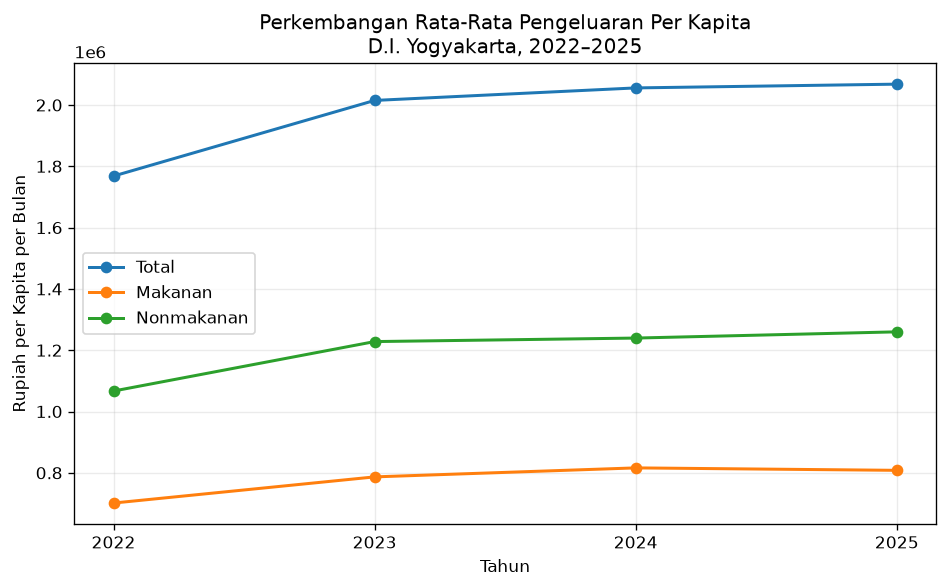

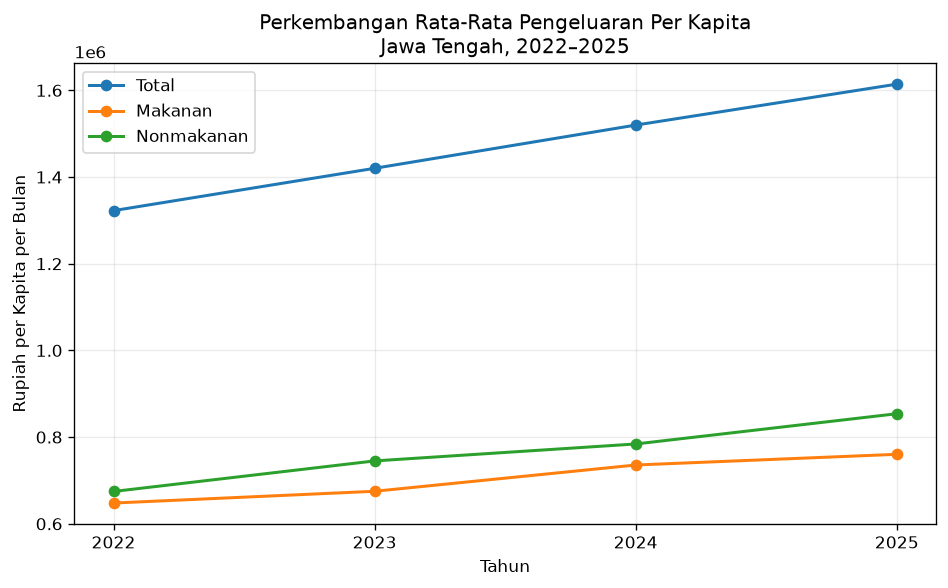

In [5]:
def plot_trend(tabel, provinsi):
    temp = tabel[tabel["Provinsi"].eq(provinsi)]

    fig, ax = plt.subplots(figsize=(8, 5))

    for component in ["Total", "Makanan", "Nonmakanan"]:
        d = temp[temp["Komponen"].eq(component)]

        ax.plot(
            d["Tahun"],
            d["Rata-rata"],
            marker="o",
            linewidth=1.8,
            label=component
        )

    ax.set_title(
        f"Perkembangan Rata-Rata Pengeluaran Per Kapita\n{provinsi}, 2022–2025"
    )
    ax.set_xlabel("Tahun")
    ax.set_ylabel("Rupiah per Kapita per Bulan")
    ax.set_xticks([2022, 2023, 2024, 2025])
    ax.legend()
    ax.grid(alpha=0.25)

    fig.tight_layout()
    fig.savefig(
        FIG_PATH / f"tren_{provinsi.replace('.', '').replace(' ', '_')}.png",
        bbox_inches="tight"
    )

    plt.show()


for prov in PROV_ORDER:
    plot_trend(tabel_tren, PROV_LABEL[prov])


### Distribusi pengeluaran 2025


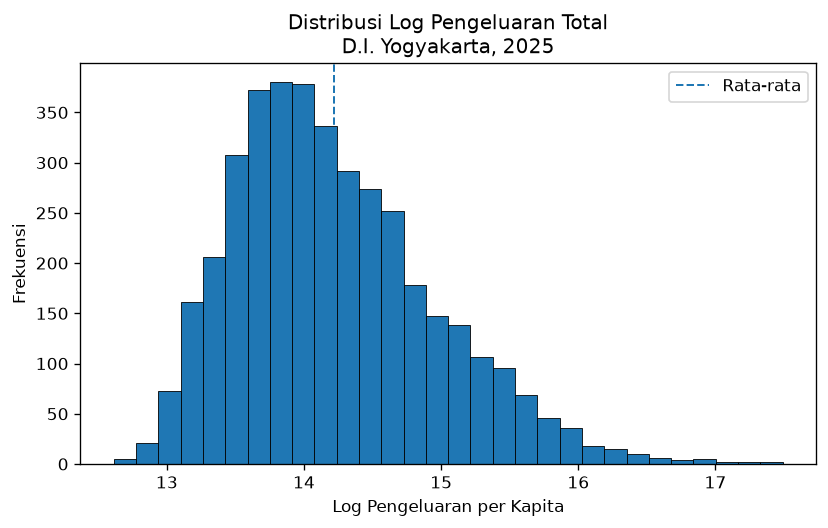

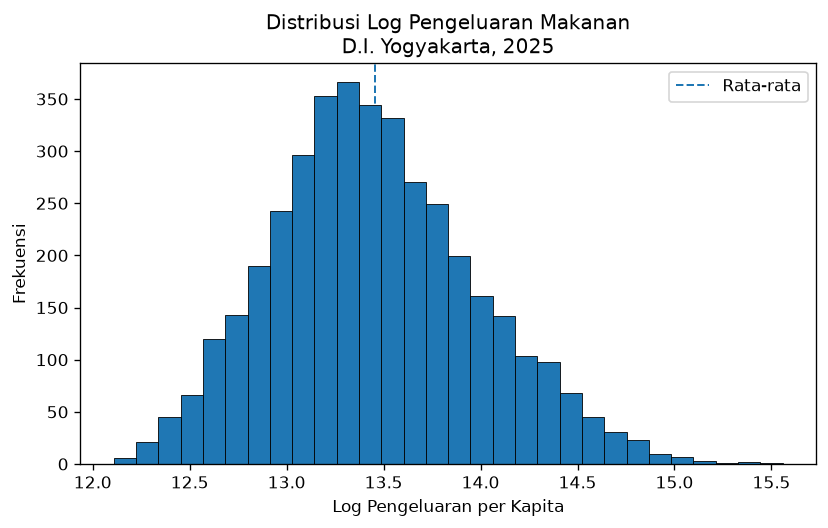

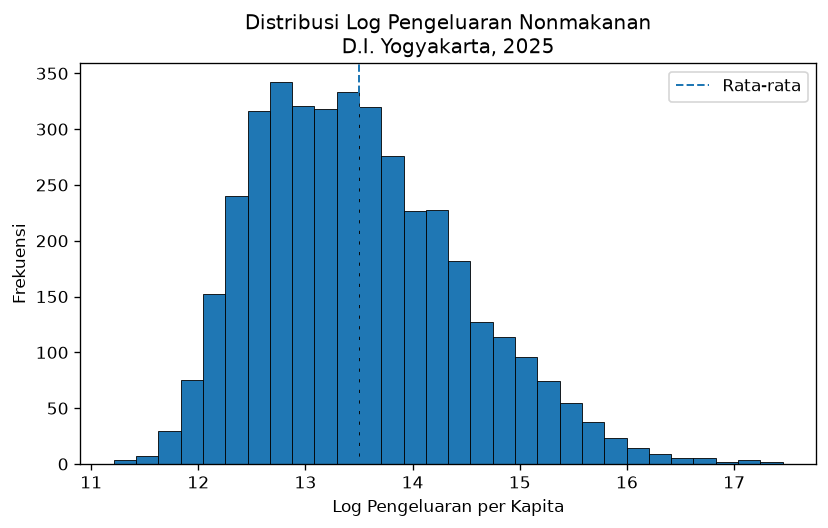

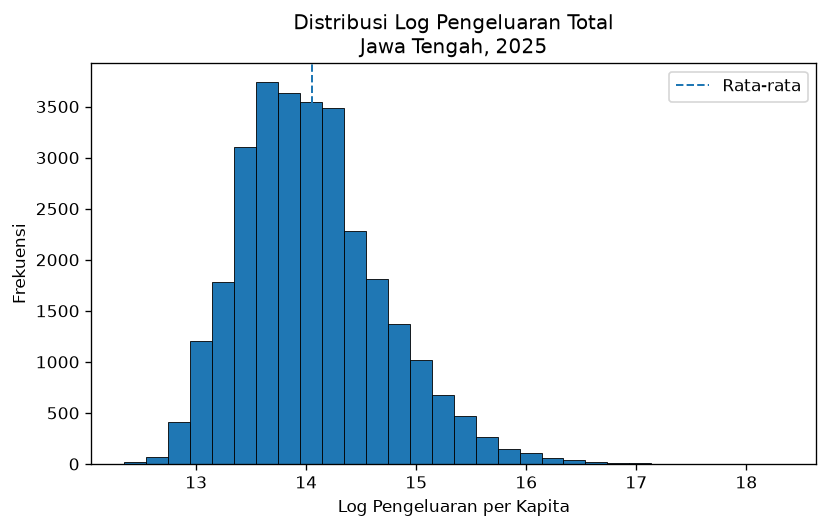

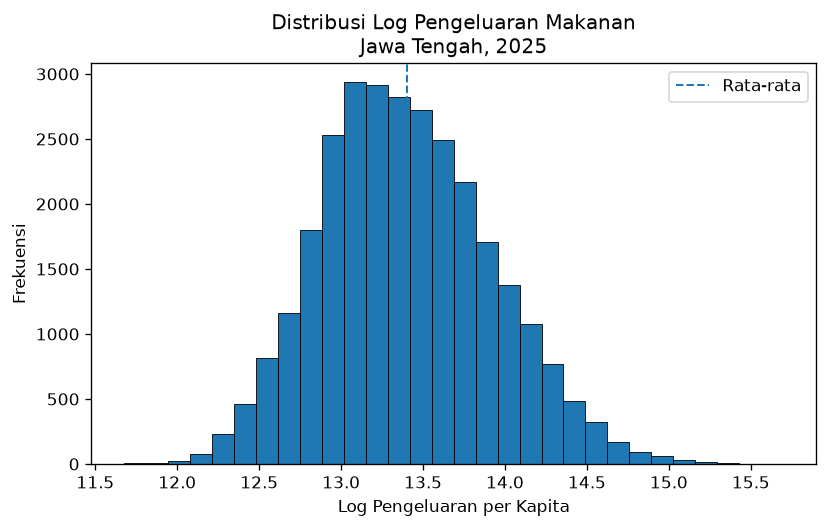

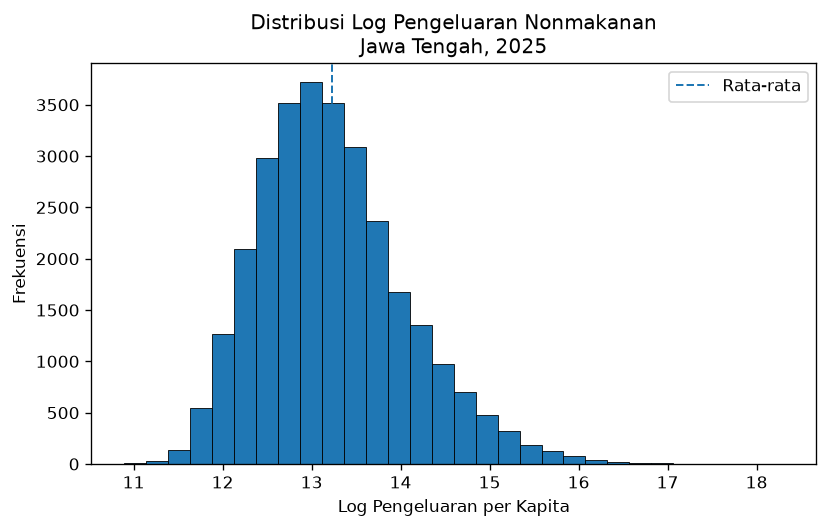

In [6]:
def plot_distribution_log(df, provinsi):
    variables = {
        "Total": "lpcexp",
        "Makanan": "lfood",
        "Nonmakanan": "lnonfood",
    }

    for label, var in variables.items():
        x = df[var].dropna()

        fig, ax = plt.subplots(figsize=(7, 4.5))
        ax.hist(x, bins=30, edgecolor="black", linewidth=0.5)
        ax.axvline(x.mean(), linestyle="--", linewidth=1.2, label="Rata-rata")

        ax.set_title(f"Distribusi Log Pengeluaran {label}\n{provinsi}, 2025")
        ax.set_xlabel("Log Pengeluaran per Kapita")
        ax.set_ylabel("Frekuensi")
        ax.legend()

        fig.tight_layout()
        fig.savefig(
            FIG_PATH / f"distribusi_log_{provinsi.replace('.', '').replace(' ', '_')}_{label.lower()}.png",
            bbox_inches="tight"
        )

        plt.show()


for prov in PROV_ORDER:
    plot_distribution_log(data_eda[prov][2025], PROV_LABEL[prov])


Demografis

In [19]:
def demographic_table(data_eda):
    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]
        total_art = df["h_hhcount"].sum()

        rows.append({
            "Provinsi": PROV_LABEL[prov],
            "Jumlah ART": total_art,
            "Rata-rata Jumlah ART": df["h_hhcount"].mean(),
            "Laki-laki (%)": df["h_nmale"].sum() / total_art * 100,
            "Perempuan (%)": df["h_nfemale"].sum() / total_art * 100,
            "Usia 0–4 tahun (%)": df["h_nage04"].sum() / total_art * 100,
            "Usia 5–19 tahun (%)": df["h_nage519"].sum() / total_art * 100,
            "Usia 20–64 tahun (%)": df["h_nage2064"].sum() / total_art * 100,
            "Usia ≥65 tahun (%)": df["h_nage65up"].sum() / total_art * 100,
        })

    return pd.DataFrame(rows)


def marital_table(data_eda):
    vars_ = {
        "Belum kawin (%)": "h_notmarried",
        "Kawin (%)": "h_married",
        "Cerai hidup (%)": "h_divorced",
        "Cerai mati (%)": "h_widowed",
    }

    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]
        total_art = df["h_hhcount"].sum()

        row = {"Provinsi": PROV_LABEL[prov]}

        for label, var in vars_.items():
            row[label] = df[var].sum() / total_art * 100

        rows.append(row)

    return pd.DataFrame(rows)


tabel_demografi = demographic_table(data_eda)
tabel_perkawinan = marital_table(data_eda)

display(tabel_demografi.round(2))
display(tabel_perkawinan.round(2))


,Provinsi,Jumlah ART,Rata-rata Jumlah ART,Laki-laki (%),Perempuan (%),Usia 0–4 tahun (%),Usia 5–19 tahun (%),Usia 20–64 tahun (%),Usia ≥65 tahun (%)
0,D.I. Yogyakarta,12278,3.12,49.25,50.75,4.79,21.09,60.95,13.16
1,Jawa Tengah,95377,3.26,49.78,50.22,6.13,23.42,60.85,9.61


,Provinsi,Belum kawin (%),Kawin (%),Cerai hidup (%),Cerai mati (%)
0,D.I. Yogyakarta,38.57,52.04,2.08,7.31
1,Jawa Tengah,38.80,52.34,1.94,6.92


Partisipasi Sekolah dan Pendidikan

In [20]:
def school_table(data_eda):
    vars_ = {
        "Tidak/belum pernah sekolah (%)": "h_neverschool",
        "Masih sekolah (%)": "h_stillschool",
        "Tidak bersekolah lagi (%)": "h_notschool",
    }

    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]

        total_school = (
            df["h_neverschool"].sum()
            + df["h_stillschool"].sum()
            + df["h_notschool"].sum()
        )

        row = {
            "Provinsi": PROV_LABEL[prov],
            "Jumlah ART tercakup": total_school,
        }

        for label, var in vars_.items():
            row[label] = df[var].sum() / total_school * 100

        rows.append(row)

    return pd.DataFrame(rows)


def education_table(data_eda):
    vars_ = {
        "Tidak/belum memiliki ijazah (%)": "h_notgrad",
        "SD/sederajat (%)": "h_ngrad_sd",
        "SMP/sederajat (%)": "h_ngrad_smp",
        "SMA/sederajat (%)": "h_ngrad_sma",
        "Diploma (%)": "h_ngrad_d",
        "Sarjana (%)": "h_ngrad_s",
    }

    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]
        row = {"Provinsi": PROV_LABEL[prov]}

        for label, var in vars_.items():
            row[label] = df[var].mean() * 100

        rows.append(row)

    return pd.DataFrame(rows)


tabel_sekolah = school_table(data_eda)
tabel_pendidikan = education_table(data_eda)

display(tabel_sekolah.round(2))
display(tabel_pendidikan.round(2))


,Provinsi,Jumlah ART tercakup,Tidak/belum pernah sekolah (%),Masih sekolah (%),Tidak bersekolah lagi (%)
0,D.I. Yogyakarta,11690,5.21,21.48,73.31
1,Jawa Tengah,89532,5.58,21.11,73.31


,Provinsi,Tidak/belum memiliki ijazah (%),SD/sederajat (%),SMP/sederajat (%),SMA/sederajat (%),Diploma (%),Sarjana (%)
0,D.I. Yogyakarta,22.69,16.73,15.57,31.17,3.30,10.53
1,Jawa Tengah,29.63,26.09,17.05,20.36,1.54,5.34


Ketenagakerjaan

In [21]:
def employment_sector_table(data_eda):
    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]

        values = {
            "Pertanian (%)": df[[f"h_sec1_stat{i}" for i in range(1, 7)]].sum().sum(),
            "Industri dan Konstruksi (%)": df[[f"h_sec2_stat{i}" for i in range(1, 7)]].sum().sum(),
            "Perdagangan dan Jasa Lainnya (%)": df[[f"h_sec3_stat{i}" for i in range(1, 7)]].sum().sum(),
        }

        total = sum(values.values())

        row = {"Provinsi": PROV_LABEL[prov]}

        for label, value in values.items():
            row[label] = value / total * 100 if total > 0 else np.nan

        rows.append(row)

    return pd.DataFrame(rows)


def employment_status_table(data_eda):
    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]

        counts = {}

        for stat in range(1, 7):
            cols = [f"h_sec{sec}_stat{stat}" for sec in range(1, 4)]
            counts[stat] = df[cols].sum().sum()

        total = sum(counts.values())

        row = {"Provinsi": PROV_LABEL[prov]}

        for stat, value in counts.items():
            row[f"Status {stat} (%)"] = value / total * 100 if total > 0 else np.nan

        rows.append(row)

    return pd.DataFrame(rows)


tabel_sektor = employment_sector_table(data_eda)
tabel_status_kerja = employment_status_table(data_eda)

display(tabel_sektor.round(2))
display(tabel_status_kerja.round(2))


,Provinsi,Pertanian (%),Industri dan Konstruksi (%),Perdagangan dan Jasa Lainnya (%)
0,D.I. Yogyakarta,56.30,8.31,35.39
1,Jawa Tengah,59.19,11.17,29.65


,Provinsi,Status 1 (%),Status 2 (%),Status 3 (%),Status 4 (%),Status 5 (%),Status 6 (%)
0,D.I. Yogyakarta,47.17,6.15,0.72,8.99,4.93,32.04
1,Jawa Tengah,50.81,4.59,0.87,15.42,3.27,25.03


Perumahan dan Utilitas

In [22]:
HOUSING_GROUPS = {
    "Kepemilikan bangunan": [f"h_house{i}" for i in range(1, 5)],
    "Lantai": [f"h_floor{i}" for i in range(1, 5)],
    "Dinding": [f"h_wall{i}" for i in range(1, 5)],
    "Atap": [f"h_roof{i}" for i in range(1, 5)],
    "Air minum": [f"h_dwater{i}" for i in range(1, 6)],
    "Penerangan": [f"h_lighting{i}" for i in range(1, 4)],
    "Daya listrik": [f"h_epower{i}" for i in range(1, 4)],
    "Bahan bakar memasak": [f"h_cookingfuel{i}" for i in range(1, 6)],
    "Fasilitas toilet": [f"h_toiltype{i}" for i in range(1, 7)],
    "Pembuangan akhir": [f"h_septic{i}" for i in range(1, 6)],
}


def housing_table(data_eda):
    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]

        for group_name, cols in HOUSING_GROUPS.items():
            available = [c for c in cols if c in df.columns]

            for col in available:
                rows.append({
                    "Provinsi": PROV_LABEL[prov],
                    "Aspek": group_name,
                    "Kategori": col,
                    "Persentase Rumah Tangga": df[col].mean() * 100,
                })

    return pd.DataFrame(rows)


tabel_perumahan = housing_table(data_eda)

display(tabel_perumahan.round(2))


,Provinsi,Aspek,Kategori,Persentase Rumah Tangga
0,D.I. Yogyakarta,Kepemilikan bangunan,h_house1,77.48
1,D.I. Yogyakarta,Kepemilikan bangunan,h_house2,13.38
2,D.I. Yogyakarta,Kepemilikan bangunan,h_house3,8.96
3,D.I. Yogyakarta,Kepemilikan bangunan,h_house4,0.18
4,D.I. Yogyakarta,Lantai,h_floor1,74.79
...,...,...,...,...
81,Jawa Tengah,Pembuangan akhir,h_septic1,75.12
82,Jawa Tengah,Pembuangan akhir,h_septic2,6.41
83,Jawa Tengah,Pembuangan akhir,h_septic3,0.00
84,Jawa Tengah,Pembuangan akhir,h_septic4,1.05


Kepemilikan Aset

In [23]:
ASSET_VARS = {
    "Tabung gas >=5,5 kg": "h_asset_lpg5kg",
    "Kulkas": "h_asset_fridge",
    "AC": "h_asset_ac",
    "Pemanas air": "h_asset_wheater",
    "Telepon": "h_asset_phone",
    "Komputer/laptop": "h_asset_computer",
    "Emas/perhiasan": "h_asset_jewelry",
    "Sepeda motor": "h_asset_motorcycle",
    "Perahu": "h_asset_boat",
    "Perahu motor": "h_asset_motorboat",
    "Mobil": "h_asset_car",
    "Televisi": "h_asset_tv",
    "Smartphone": "h_asset_smartphone",
    "Tanah": "h_asset_land",
}


def asset_table(data_eda):
    rows = []

    for label, var in ASSET_VARS.items():
        row = {"Aset": label}

        for prov in PROV_ORDER:
            df = data_eda[prov][2025]
            row[PROV_LABEL[prov]] = df[var].mean() * 100

        rows.append(row)

    return pd.DataFrame(rows)


tabel_aset = asset_table(data_eda)

display(tabel_aset.round(2))


,Aset,D.I. Yogyakarta,Jawa Tengah
0,"Tabung gas >=5,5 kg",13.35,6.70
1,Kulkas,72.78,73.03
2,AC,11.53,6.29
3,Pemanas air,3.94,2.92
4,Telepon,2.06,0.80
5,Komputer/laptop,29.70,16.09
6,Emas/perhiasan,22.34,16.78
7,Sepeda motor,84.62,83.49
8,Perahu,0.25,0.52
9,Perahu motor,0.36,0.59


## 5. Hubungan Karakteristik Sosial Ekonomi dengan Pengeluaran Per Kapita

Analisis pada bagian ini menggunakan **data tahun 2025 tanpa bobot**.

Tiga variabel respons yang diamati:
1. Pengeluaran per kapita total
2. Pengeluaran per kapita makanan
3. Pengeluaran per kapita nonmakanan

Karakteristik sosial ekonomi diperlakukan sebagai variabel pada tingkat rumah tangga. Untuk variabel yang berasal dari karakteristik anggota rumah tangga, nilai yang digunakan merupakan ukuran yang telah diagregasi pada tingkat rumah tangga, seperti proporsi anggota rumah tangga.


,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,3–4 orang,1858,1801302.90,747557.28,1053745.61
1,D.I. Yogyakarta,≥5 orang,637,1355963.82,618996.14,736967.68
2,D.I. Yogyakarta,1–2 orang,1444,2725415.54,969413.19,1756002.35
3,Jawa Tengah,1–2 orang,9348,2088487.27,925326.09,1163161.19
4,Jawa Tengah,3–4 orang,14934,1479540.38,720380.40,759159.98
5,Jawa Tengah,≥5 orang,4993,1129484.43,570886.13,558598.30


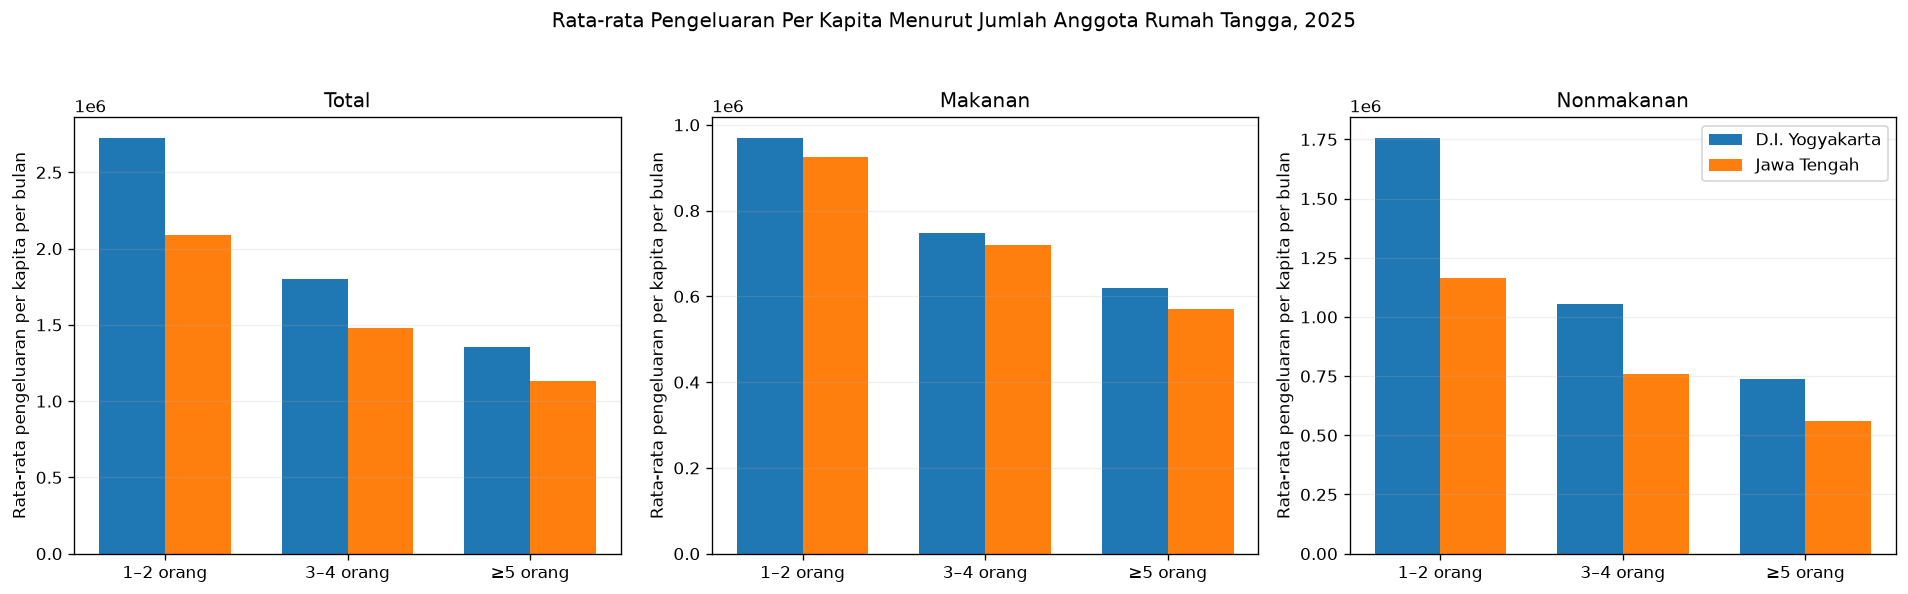

,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,>50–75%,980,1704342.78,724230.18,980112.60
1,D.I. Yogyakarta,>25–50%,1275,1641110.33,694819.08,946291.26
2,D.I. Yogyakarta,>75–100%,1190,2714419.65,1003277.63,1711142.03
3,D.I. Yogyakarta,0–25%,494,2334491.49,796668.72,1537822.77
4,Jawa Tengah,>75–100%,7827,2085140.13,937529.45,1147610.68
5,Jawa Tengah,0–25%,2661,1769084.21,777763.49,991320.72
6,Jawa Tengah,>25–50%,10501,1330715.34,651822.21,678893.12
7,Jawa Tengah,>50–75%,8286,1479167.78,724847.56,754320.22


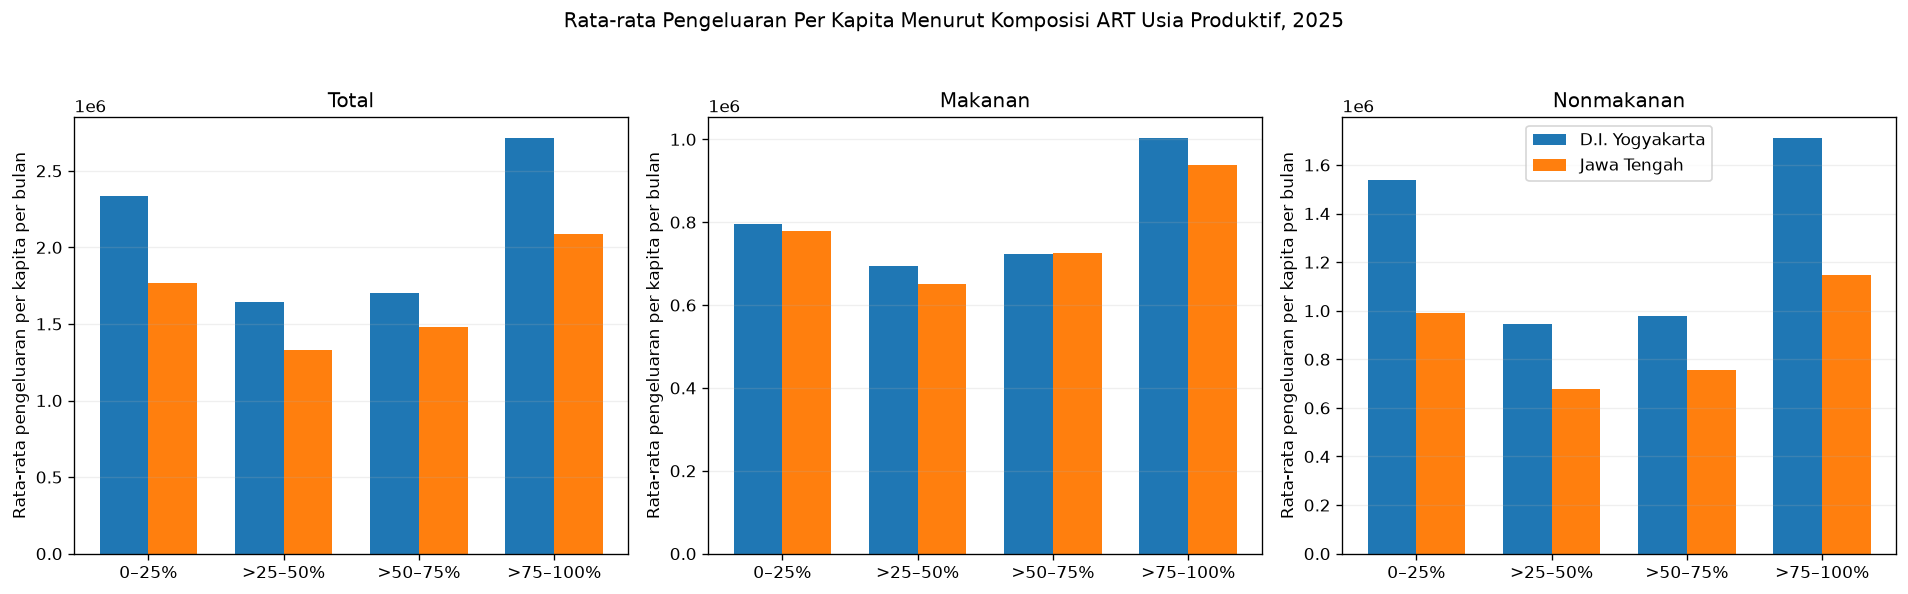

,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,>50–75%,568,2130283.26,832090.40,1298192.87
1,D.I. Yogyakarta,>25–50%,1164,1681642.52,714150.41,967492.11
2,D.I. Yogyakarta,>75–100%,806,3907925.83,1183518.49,2724407.34
3,D.I. Yogyakarta,0–25%,1401,1305388.13,660442.75,644945.38
4,Jawa Tengah,0–25%,17080,1271756.21,674008.18,597748.03
5,Jawa Tengah,>25–50%,7202,1618548.55,758428.14,860120.41
6,Jawa Tengah,>50–75%,2544,2104598.15,882312.60,1222285.55
7,Jawa Tengah,>75–100%,2449,3481286.39,1241192.81,2240093.58


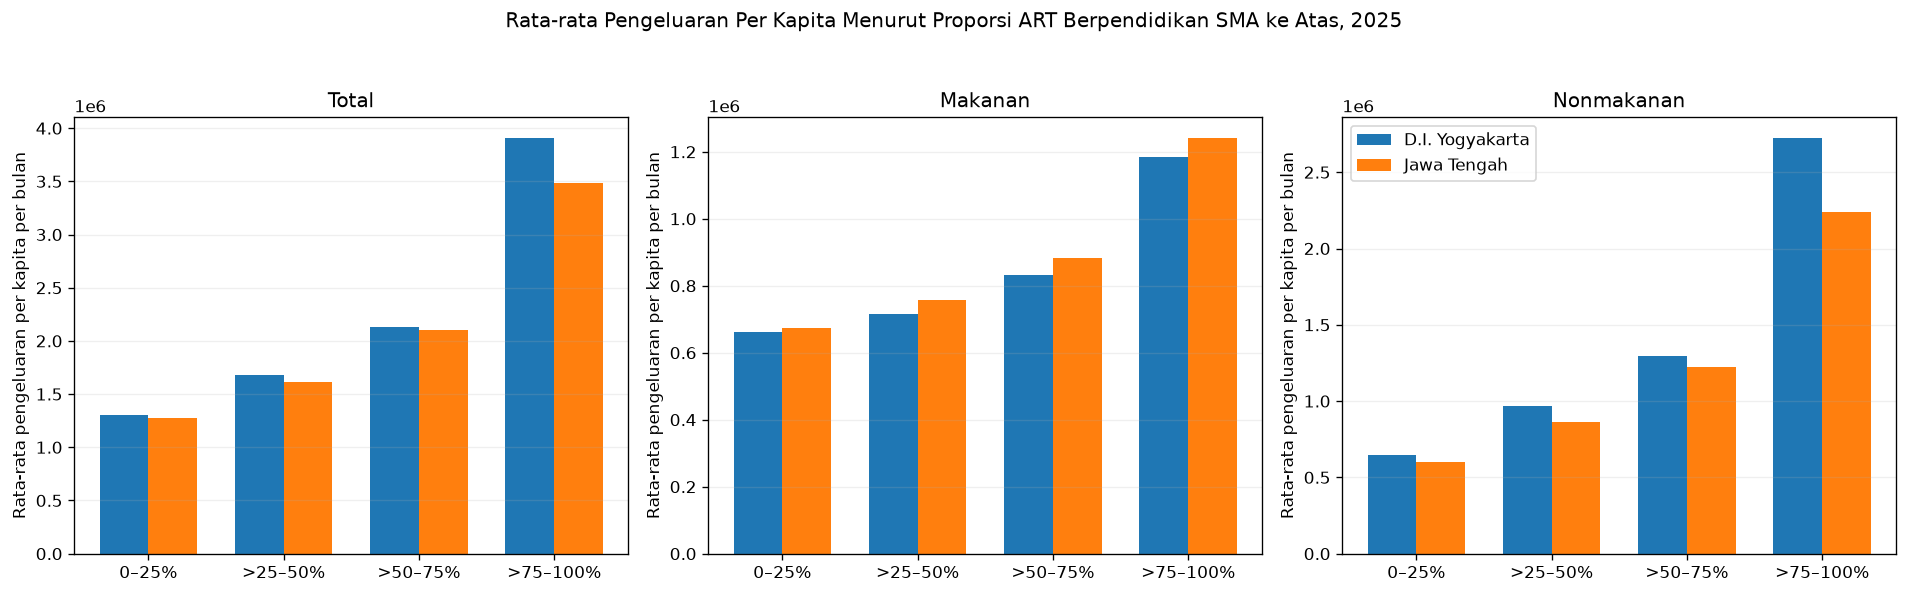

,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,>75–100%,3939,2068055.29,808097.14,1259958.15
1,Jawa Tengah,>75–100%,29275,1614283.55,760326.00,853957.55


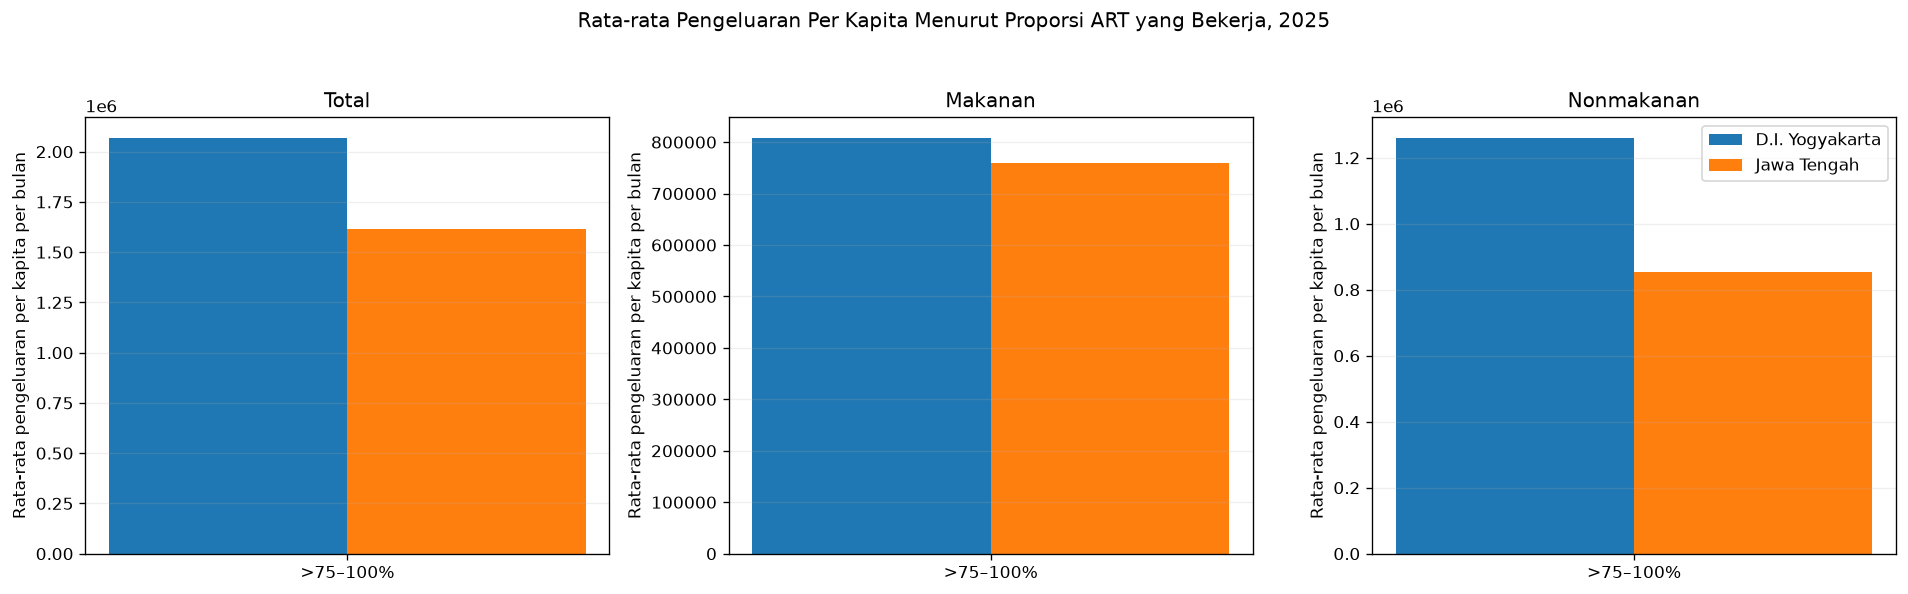


=== Kepemilikan Rumah ===


,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Milik sendiri,3052,1977262.66,785087.78,1192174.88
1,D.I. Yogyakarta,Lainnya,887,2380455.62,887267.99,1493187.63
2,Jawa Tengah,Milik sendiri,25389,1617480.40,759883.31,857597.08
3,Jawa Tengah,Lainnya,3886,1593397.08,763218.25,830178.83


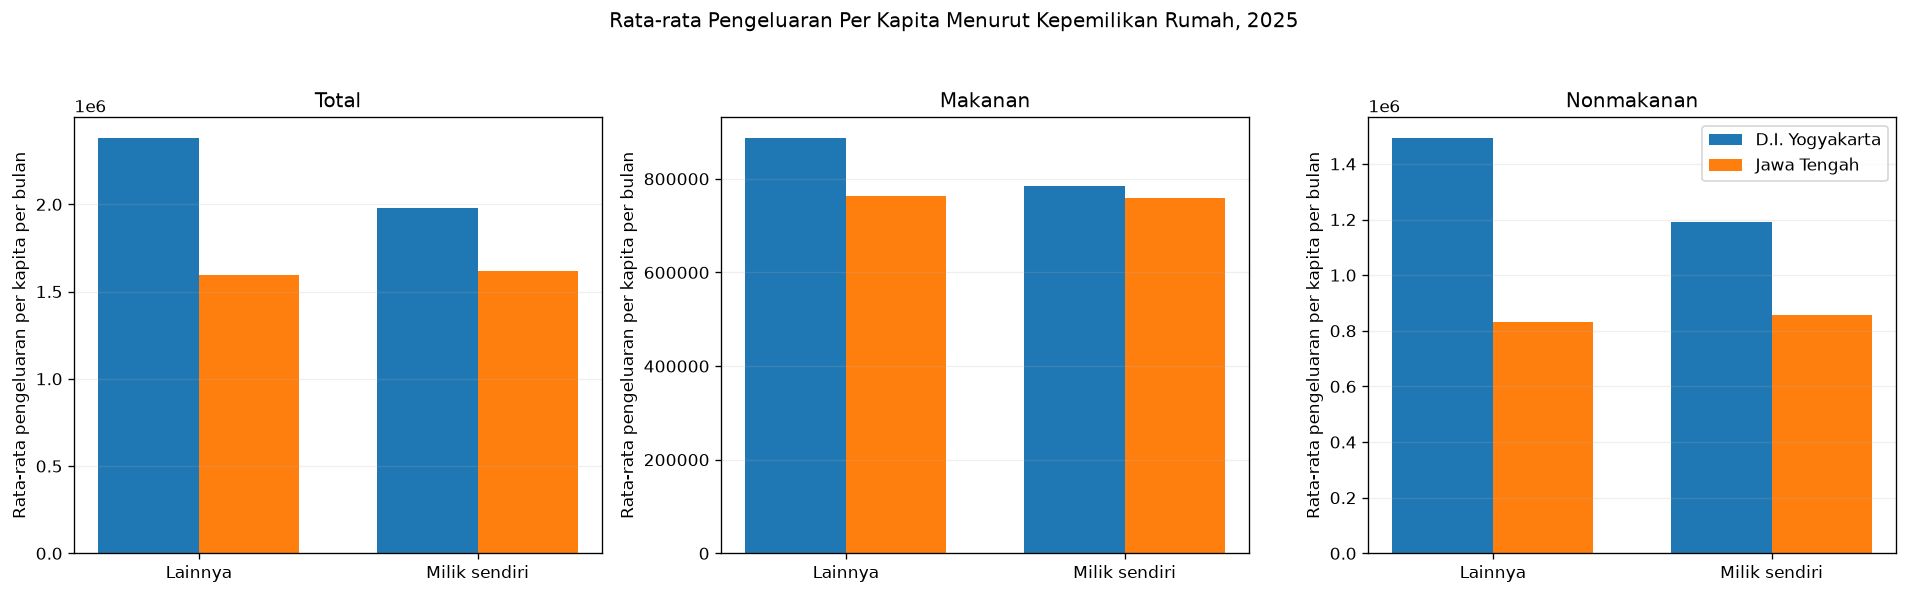


=== Jenis Lantai ===


,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Keramik dan sejenisnya,2946,2382672.78,876166.67,1506506.11
1,D.I. Yogyakarta,Lainnya,993,1134658.39,606150.67,528507.72
2,Jawa Tengah,Keramik dan sejenisnya,21802,1786215.89,806359.96,979855.93
3,Jawa Tengah,Lainnya,7473,1112681.91,626024.84,486657.07


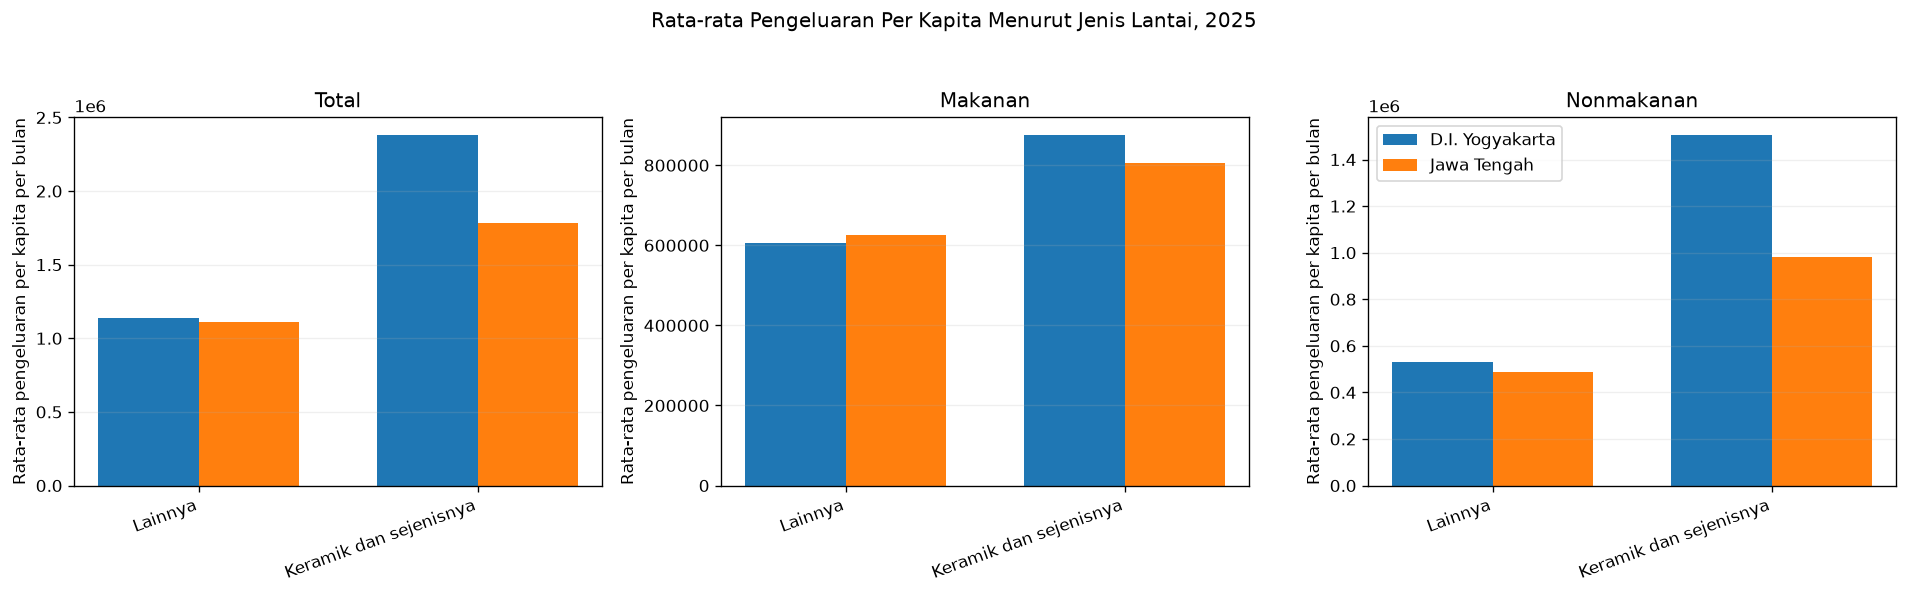


=== Jenis Dinding ===


,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Tembok,3796,2100242.56,815390.37,1284852.19
1,D.I. Yogyakarta,Lainnya,143,1213629.43,614494.97,599134.46
2,Jawa Tengah,Tembok,25944,1672346.02,774399.70,897946.33
3,Jawa Tengah,Lainnya,3331,1162055.11,650710.86,511344.25


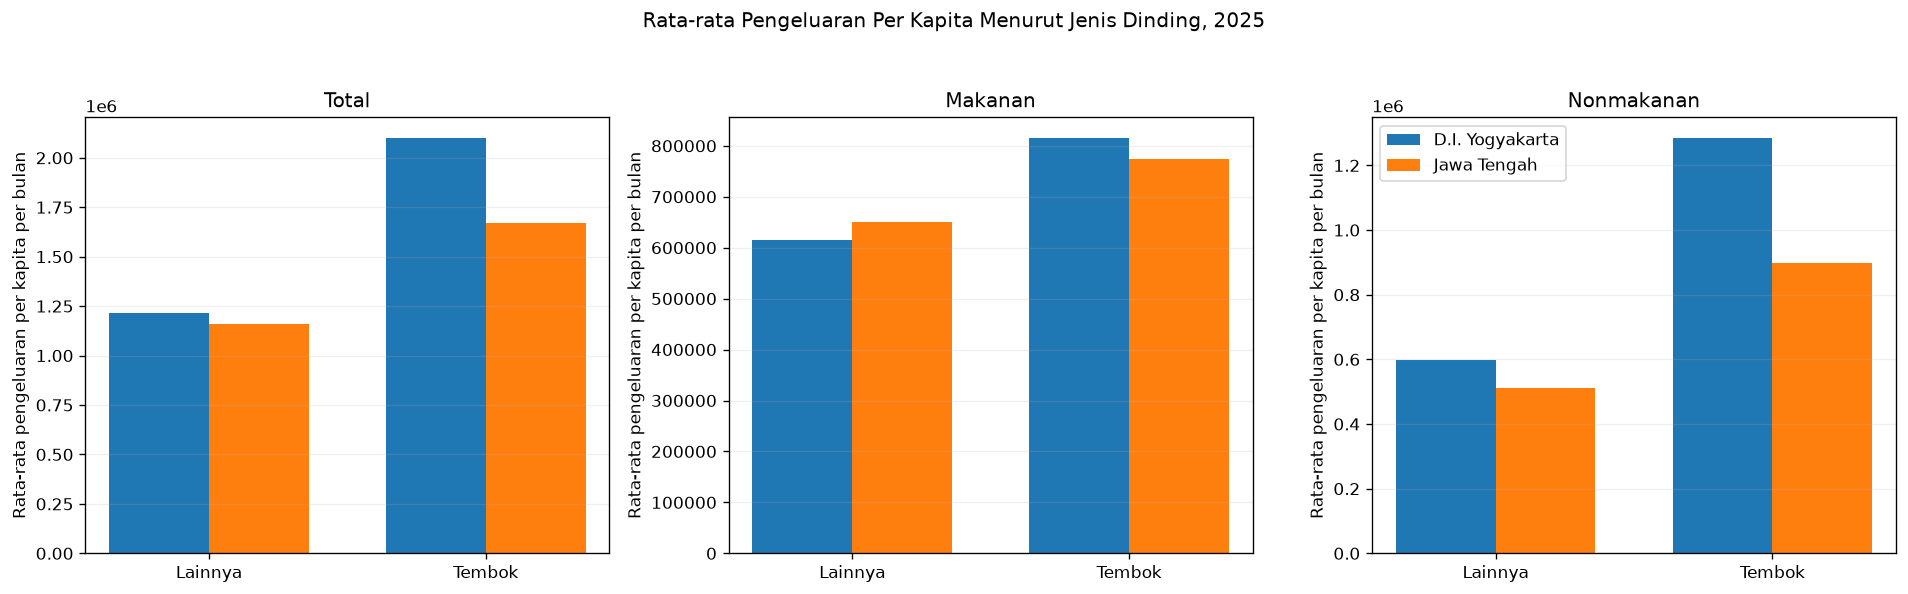


=== Jenis Atap ===


,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Lainnya,3872,2042665.66,803242.88,1239422.79
1,D.I. Yogyakarta,Beton/genteng,67,3535348.27,1088629.95,2446718.32
2,Jawa Tengah,Lainnya,28806,1602595.37,758062.43,844532.94
3,Jawa Tengah,Beton/genteng,469,2332171.76,899354.40,1432817.36


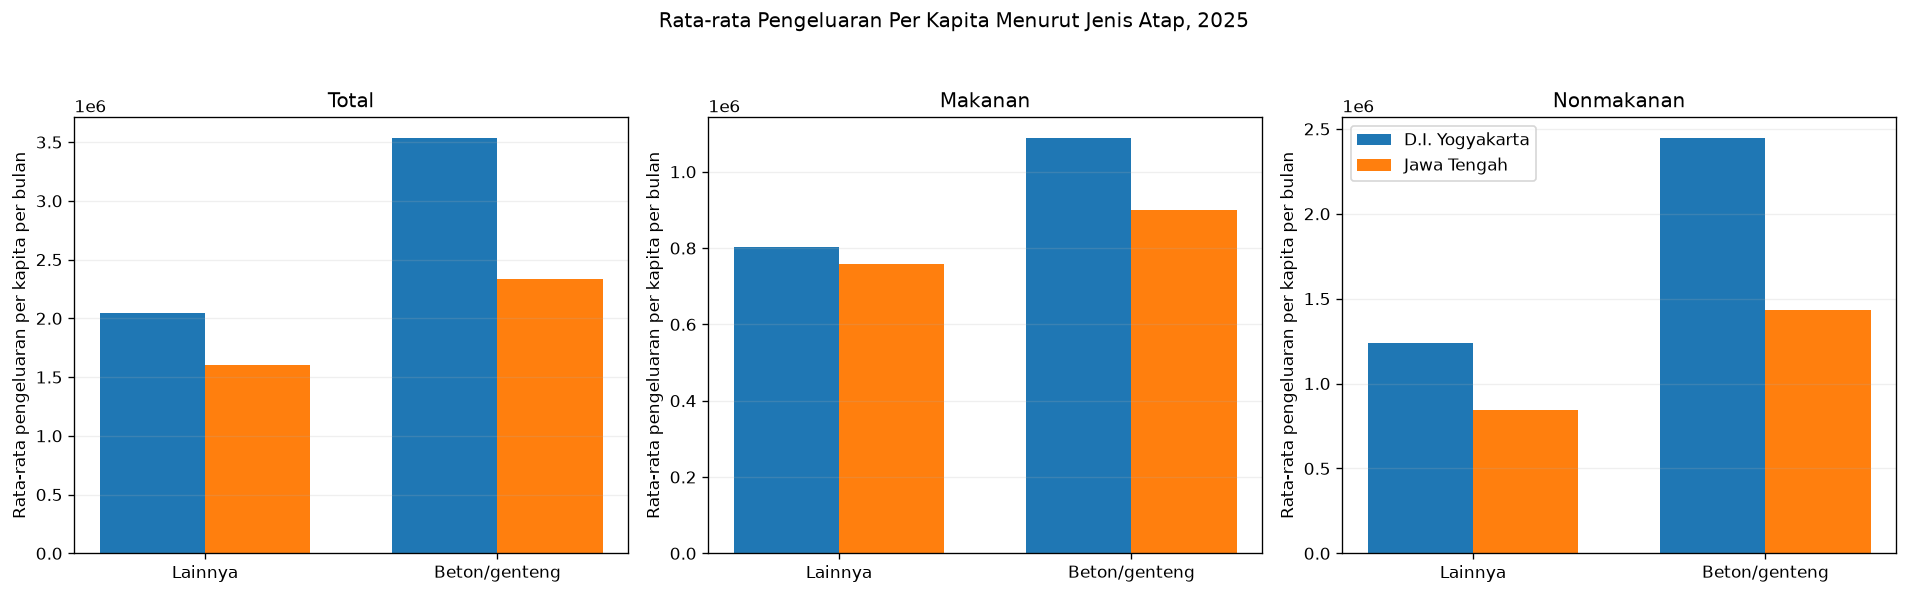


=== Jenis Sanitasi ===


,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Tangki septik,3086,2101655.32,811427.35,1290227.98
1,D.I. Yogyakarta,Lainnya,853,1946496.43,796049.04,1150447.38
2,Jawa Tengah,Tangki septik,21991,1709035.46,786751.61,922283.85
3,Jawa Tengah,Lainnya,7284,1328219.66,680544.88,647674.78


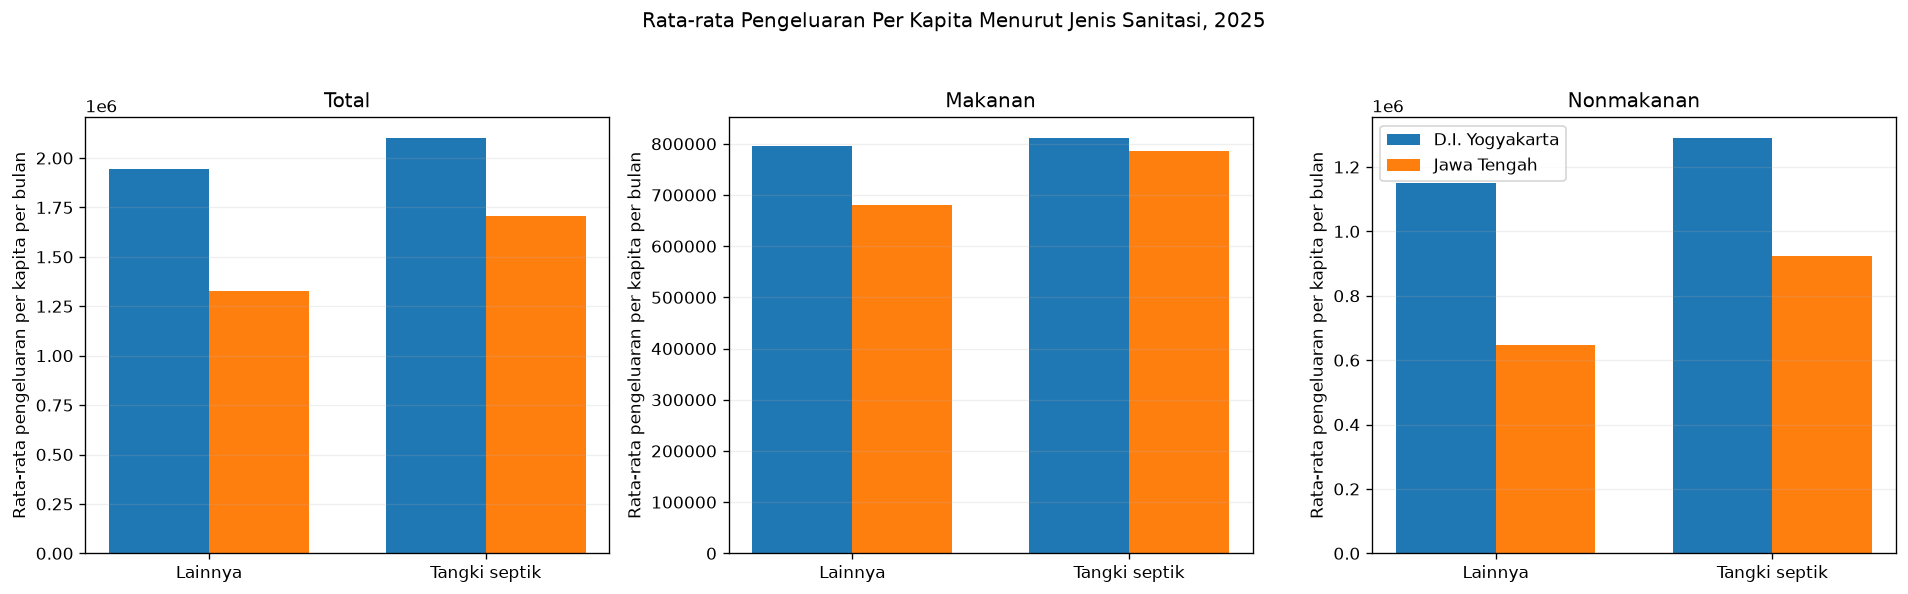

Hasil hubungan X–Y disimpan di: d:\.STIS 64\SKRIPSI\Skripsi\PMT\output\eda_x_y\hubungan_X_Y_2025.xlsx


In [26]:
# ============================================================
# HUBUNGAN KARAKTERISTIK SOSIAL EKONOMI DENGAN Y
# Data 2025, tanpa bobot/FWT
# ============================================================

Y_VARS = {
    "Total": "total_pc_adj",
    "Makanan": "food_pc_adj",
    "Nonmakanan": "nonfood_pc_adj",
}


def make_grouped_mean_table(data_eda, feature_col):
    rows = []
    for prov in PROV_ORDER:
        df = data_eda[prov][2025].copy()
        if feature_col not in df.columns:
            continue
        for category in df[feature_col].dropna().unique():
            d = df[df[feature_col] == category]
            row = {"Provinsi": PROV_LABEL[prov], "Kategori": category, "N": len(d)}
            for y_label, y_col in Y_VARS.items():
                row[f"Rata-rata {y_label}"] = d[y_col].mean()
            rows.append(row)
    return pd.DataFrame(rows)


def plot_grouped_mean_x_y(data_eda, feature_name, feature_col, filename_prefix,
                           category_order=None, rotate=0):
    rows = []
    for prov in PROV_ORDER:
        df = data_eda[prov][2025].copy()
        if feature_col not in df.columns:
            continue
        for category in df[feature_col].dropna().unique():
            d = df[df[feature_col] == category]
            for y_label, y_col in Y_VARS.items():
                rows.append({
                    "Provinsi": PROV_LABEL[prov],
                    "Kategori": str(category),
                    "Y": y_label,
                    "Mean": d[y_col].mean(),
                })

    plot_df = pd.DataFrame(rows)
    if plot_df.empty:
        return

    if category_order is None:
        categories = list(plot_df["Kategori"].drop_duplicates())
    else:
        categories = [str(c) for c in category_order]

    categories = [c for c in categories if c in plot_df["Kategori"].unique()]
    x = np.arange(len(categories))
    width = 0.36

    fig, axes = plt.subplots(1, 3, figsize=(16, 5))

    for ax, y_label in zip(axes, Y_VARS.keys()):
        temp = plot_df[plot_df["Y"] == y_label]

        for i, prov in enumerate(PROV_ORDER):
            prov_label = PROV_LABEL[prov]
            d = (
                temp[temp["Provinsi"] == prov_label]
                .set_index("Kategori")
                .reindex(categories)
            )
            means = d["Mean"].to_numpy(dtype=float)
            offset = (i - 0.5) * width
            ax.bar(x + offset, means, width=width, label=prov_label)

        ax.set_title(y_label)
        ax.set_xticks(x)
        ax.set_xticklabels(categories, rotation=rotate, ha="right" if rotate else "center")
        ax.set_ylabel("Rata-rata pengeluaran per kapita per bulan")
        ax.grid(axis="y", alpha=0.2)

    axes[-1].legend()
    fig.suptitle(f"Rata-rata Pengeluaran Per Kapita Menurut {feature_name}, 2025")
    fig.tight_layout(rect=[0, 0, 1, 0.94])

    safe = re.sub(r"[^A-Za-z0-9]+", "_", filename_prefix).strip("_")
    fig.savefig(FIG_PATH / f"{safe}_2025.png", bbox_inches="tight")
    plt.show()


# ============================================================
# A. JUMLAH ANGGOTA RUMAH TANGGA
# ============================================================
for prov in PROV_ORDER:
    df = data_eda[prov][2025]
    df["kategori_jumlah_art"] = pd.cut(
        pd.to_numeric(df["h_hhcount"], errors="coerce"),
        bins=[0, 2, 4, np.inf],
        labels=["1–2 orang", "3–4 orang", "≥5 orang"],
        include_lowest=True,
    )

jumlah_art_table = make_grouped_mean_table(data_eda, "kategori_jumlah_art")
display(jumlah_art_table.round(2))
plot_grouped_mean_x_y(
    data_eda,
    "Jumlah Anggota Rumah Tangga",
    "kategori_jumlah_art",
    "hubungan_jumlah_art",
    category_order=["1–2 orang", "3–4 orang", "≥5 orang"],
)


# ============================================================
# B. KOMPOSISI ART USIA PRODUKTIF (20–64 TAHUN)
# ============================================================
for prov in PROV_ORDER:
    df = data_eda[prov][2025]
    df["prop_age_produktif"] = np.where(
        df["h_hhcount"] > 0,
        df["h_nage2064"] / df["h_hhcount"],
        np.nan,
    )
    df["kategori_age_produktif"] = pd.cut(
        df["prop_age_produktif"],
        bins=[-0.001, 0.25, 0.50, 0.75, 1.0001],
        labels=["0–25%", ">25–50%", ">50–75%", ">75–100%"],
        include_lowest=True,
    )

age_prod_table = make_grouped_mean_table(data_eda, "kategori_age_produktif")
display(age_prod_table.round(2))
plot_grouped_mean_x_y(
    data_eda,
    "Komposisi ART Usia Produktif",
    "kategori_age_produktif",
    "hubungan_usia_produktif",
    category_order=["0–25%", ">25–50%", ">50–75%", ">75–100%"],
)


# ============================================================
# C. PROPORSI ART BERPENDIDIKAN SMA KE ATAS
# ============================================================
for prov in PROV_ORDER:
    df = data_eda[prov][2025]
    df["prop_sma_plus"] = df["h_ngrad_sma"] + df["h_ngrad_d"] + df["h_ngrad_s"]
    df["kategori_sma_plus"] = pd.cut(
        df["prop_sma_plus"],
        bins=[-0.001, 0.25, 0.50, 0.75, 1.0001],
        labels=["0–25%", ">25–50%", ">50–75%", ">75–100%"],
        include_lowest=True,
    )

sma_plus_table = make_grouped_mean_table(data_eda, "kategori_sma_plus")
display(sma_plus_table.round(2))
plot_grouped_mean_x_y(
    data_eda,
    "Proporsi ART Berpendidikan SMA ke Atas",
    "kategori_sma_plus",
    "hubungan_sma_plus",
    category_order=["0–25%", ">25–50%", ">50–75%", ">75–100%"],
)


# ============================================================
# D. PROPORSI ART YANG BEKERJA
# ============================================================
for prov in PROV_ORDER:
    df = data_eda[prov][2025]
    if "work_frac" in df.columns:
        df["prop_bekerja"] = pd.to_numeric(df["work_frac"], errors="coerce")
    else:
        work_count = sum(
            df[f"h_sec{sec}_stat{stat}"]
            for sec in range(1, 4)
            for stat in range(1, 7)
            if f"h_sec{sec}_stat{stat}" in df.columns
        )
        df["prop_bekerja"] = np.where(df["h_hhcount"] > 0, work_count / df["h_hhcount"], np.nan)

    df["kategori_bekerja"] = pd.cut(
        df["prop_bekerja"],
        bins=[-0.001, 0.25, 0.50, 0.75, 1.0001],
        labels=["0–25%", ">25–50%", ">50–75%", ">75–100%"],
        include_lowest=True,
    )

bekerja_table = make_grouped_mean_table(data_eda, "kategori_bekerja")
display(bekerja_table.round(2))
plot_grouped_mean_x_y(
    data_eda,
    "Proporsi ART yang Bekerja",
    "kategori_bekerja",
    "hubungan_proporsi_bekerja",
    category_order=["0–25%", ">25–50%", ">50–75%", ">75–100%"],
)


# ============================================================
# E. KONDISI PERUMAHAN
# ============================================================
HOUSING_RELATIONSHIP = {
    "Kepemilikan Rumah": ("h_house1", ["Lainnya", "Milik sendiri"]),
    "Jenis Lantai": (
        "h_floor1",
        ["Lainnya", "Keramik dan sejenisnya"],
    ),
    "Jenis Dinding": ("h_wall1", ["Lainnya", "Tembok"]),
    "Jenis Atap": ("h_roof1", ["Lainnya", "Beton/genteng"]),
    "Jenis Sanitasi": ("h_septic1", ["Lainnya", "Tangki septik"]),
}

housing_relationship_tables = {}

for label, (col, labels) in HOUSING_RELATIONSHIP.items():
    category_col = "kategori_" + re.sub(r"[^A-Za-z0-9]+", "_", label).strip("_").lower()

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]
        if col not in df.columns:
            continue
        num = pd.to_numeric(df[col], errors="coerce")

        df[category_col] = num.map({
            1: labels[1],
            0: labels[0]
        }).astype("object")

    table = make_grouped_mean_table(data_eda, category_col)
    housing_relationship_tables[label] = table

    print(f"\n=== {label} ===")
    display(table.round(2))

    plot_grouped_mean_x_y(
        data_eda,
        label,
        category_col,
        "hubungan_" + re.sub(r"[^A-Za-z0-9]+", "_", label).strip("_").lower(),
        category_order=labels,
        rotate=20 if len(labels[1]) > 20 else 0,
    )


# ============================================================
# F. EKSPOR HASIL HUBUNGAN X–Y
# ============================================================
XY_PATH = OUTPUT_PATH / "hubungan_X_Y_2025.xlsx"

with pd.ExcelWriter(XY_PATH, engine="openpyxl") as writer:
    jumlah_art_table.to_excel(writer, sheet_name="Jumlah_ART", index=False)
    age_prod_table.to_excel(writer, sheet_name="Usia_Produktif", index=False)
    sma_plus_table.to_excel(writer, sheet_name="SMA_Ke_Atas", index=False)
    bekerja_table.to_excel(writer, sheet_name="Proporsi_Bekerja", index=False)
    for label, table in housing_relationship_tables.items():
        sheet = re.sub(r"[^A-Za-z0-9]+", "_", label).strip("_")[:31]
        table.to_excel(writer, sheet_name=sheet, index=False)

print("Hasil hubungan X–Y disimpan di:", XY_PATH)



=== jogja ===


kategori_bekerja
0–25%          0
>25–50%        0
>50–75%        0
>75–100%    3939
Name: count, dtype: int64


=== jateng ===


kategori_bekerja
0–25%           0
>25–50%         0
>50–75%         0
>75–100%    29275
Name: count, dtype: int64

,Provinsi,Kategori,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,>75–100%,3939,2068055.29,808097.14,1259958.15
1,Jawa Tengah,>75–100%,29275,1614283.55,760326.00,853957.55


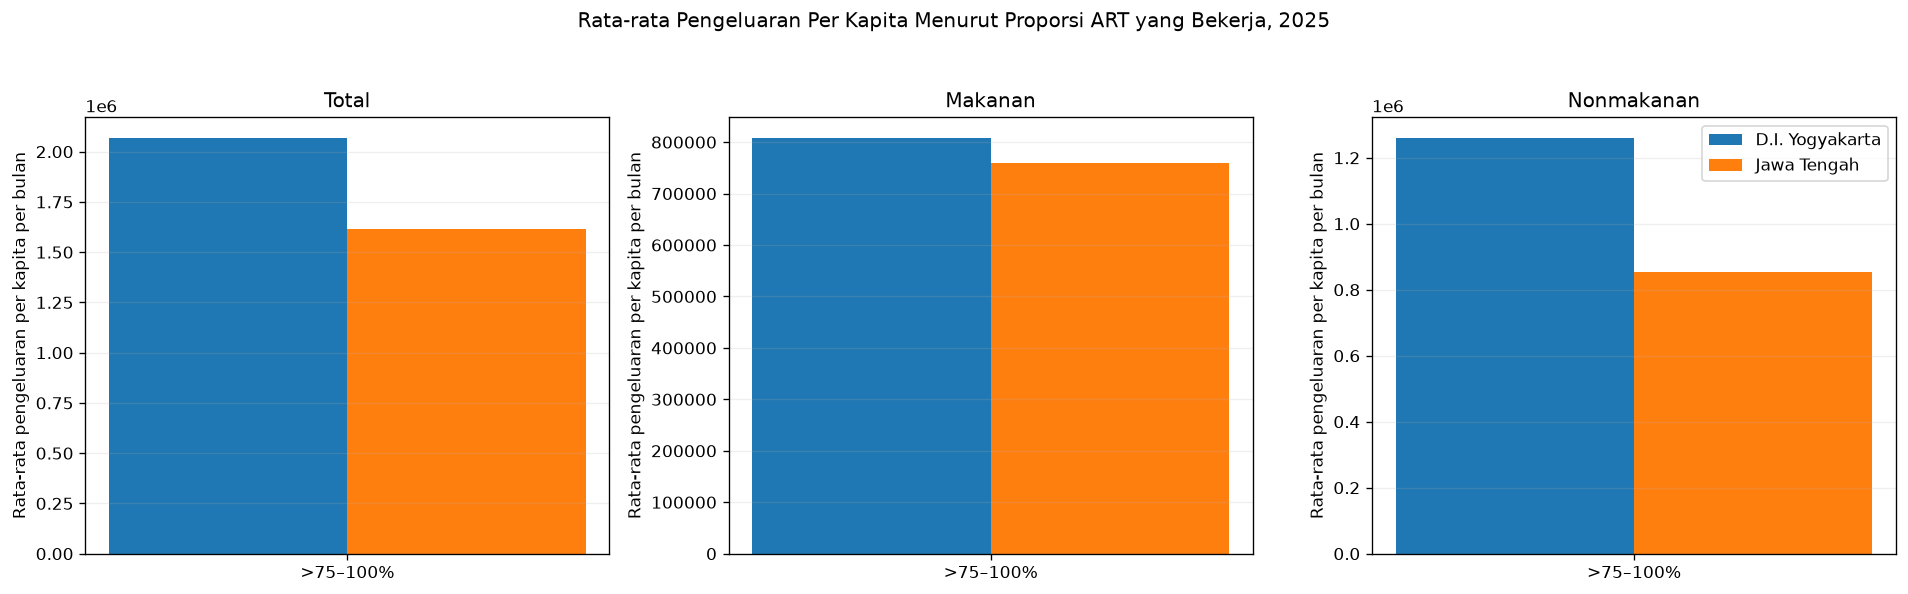

In [27]:
# ============================================================
# HUBUNGAN PROPORSI ART YANG BEKERJA DENGAN PENGELUARAN
# ============================================================

for prov in PROV_ORDER:

    df = data_eda[prov][2025]

    # Semua kolom jumlah ART berdasarkan sektor dan status pekerjaan
    work_cols = [
        f"h_sec{sec}_stat{stat}"
        for sec in range(1, 4)
        for stat in range(1, 7)
        if f"h_sec{sec}_stat{stat}" in df.columns
    ]

    # Pastikan kolom numerik
    work_data = df[work_cols].apply(
        pd.to_numeric,
        errors="coerce"
    )

    # Jumlah ART yang bekerja
    df["jumlah_art_bekerja"] = work_data.sum(axis=1, min_count=1)

    # Proporsi ART yang bekerja
    df["prop_bekerja"] = np.where(
        df["h_hhcount"] > 0,
        df["jumlah_art_bekerja"] / df["h_hhcount"],
        np.nan
    )

    # Batasi agar tidak melebihi 1 karena pembulatan/inkonsistensi data
    df["prop_bekerja"] = df["prop_bekerja"].clip(0, 1)

    # Kelompok proporsi
    df["kategori_bekerja"] = pd.cut(
        df["prop_bekerja"],
        bins=[-0.001, 0.25, 0.50, 0.75, 1.0001],
        labels=[
            "0–25%",
            ">25–50%",
            ">50–75%",
            ">75–100%"
        ],
        include_lowest=True
    )

    # Tampilkan distribusi
    print(f"\n=== {prov} ===")
    display(
        df["kategori_bekerja"]
        .value_counts(dropna=False)
        .sort_index()
    )

# ============================================================
# TABEL RATA-RATA Y MENURUT PROPORSI ART BEKERJA
# ============================================================

bekerja_table = make_grouped_mean_table(
    data_eda,
    "kategori_bekerja"
)

display(
    bekerja_table.round(2)
)

# ============================================================
# GRAFIK
# ============================================================

plot_grouped_mean_x_y(
    data_eda,
    "Proporsi ART yang Bekerja",
    "kategori_bekerja",
    "hubungan_proporsi_bekerja",
    category_order=[
        "0–25%",
        ">25–50%",
        ">50–75%",
        ">75–100%"
    ]
)

### 5.1 Demografi dan komposisi anggota rumah tangga

### 5.2 Status perkawinan, partisipasi sekolah, dan pendidikan

### 5.3 Ketenagakerjaan

""


,Provinsi,Karakteristik,Variabel X,Y,Spearman rho,N
0,D.I. Yogyakarta,Proporsi ART bekerja di pertanian,Proporsi ART bekerja di pertanian,Total,-0.3625,3939
1,D.I. Yogyakarta,Proporsi ART bekerja di pertanian,Proporsi ART bekerja di pertanian,Makanan,-0.3297,3939
2,D.I. Yogyakarta,Proporsi ART bekerja di pertanian,Proporsi ART bekerja di pertanian,Nonmakanan,-0.3488,3939
3,D.I. Yogyakarta,Proporsi ART bekerja di industri dan konstruksi,Proporsi ART bekerja di industri dan konstruksi,Total,-0.1302,3939
4,D.I. Yogyakarta,Proporsi ART bekerja di industri dan konstruksi,Proporsi ART bekerja di industri dan konstruksi,Makanan,-0.1163,3939
5,D.I. Yogyakarta,Proporsi ART bekerja di industri dan konstruksi,Proporsi ART bekerja di industri dan konstruksi,Nonmakanan,-0.1254,3939
6,D.I. Yogyakarta,Proporsi ART bekerja di perdagangan dan jasa,Proporsi ART bekerja di perdagangan dan jasa,Total,0.0686,3939
7,D.I. Yogyakarta,Proporsi ART bekerja di perdagangan dan jasa,Proporsi ART bekerja di perdagangan dan jasa,Makanan,0.0569,3939
8,D.I. Yogyakarta,Proporsi ART bekerja di perdagangan dan jasa,Proporsi ART bekerja di perdagangan dan jasa,Nonmakanan,0.0790,3939
9,Jawa Tengah,Proporsi ART bekerja di pertanian,Proporsi ART bekerja di pertanian,Total,-0.4089,29275


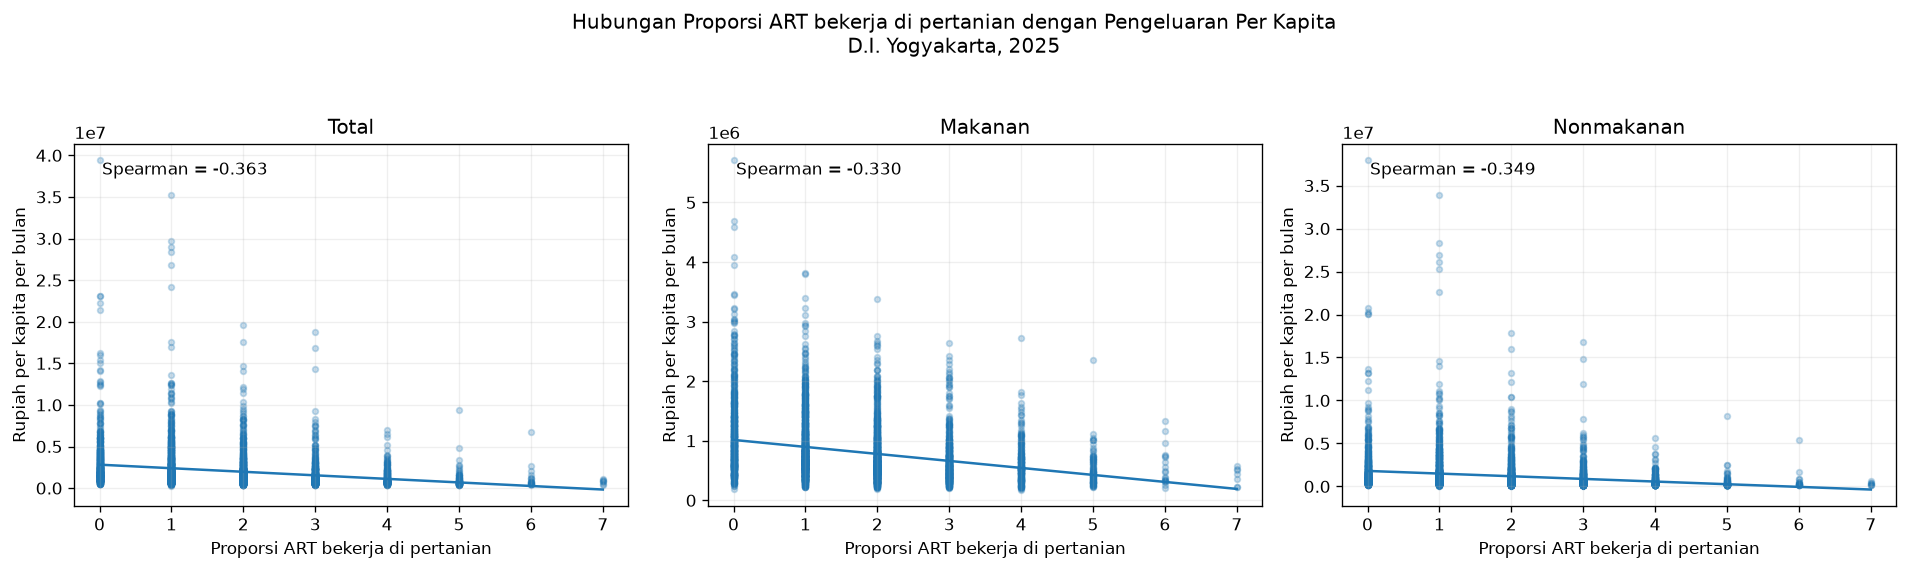

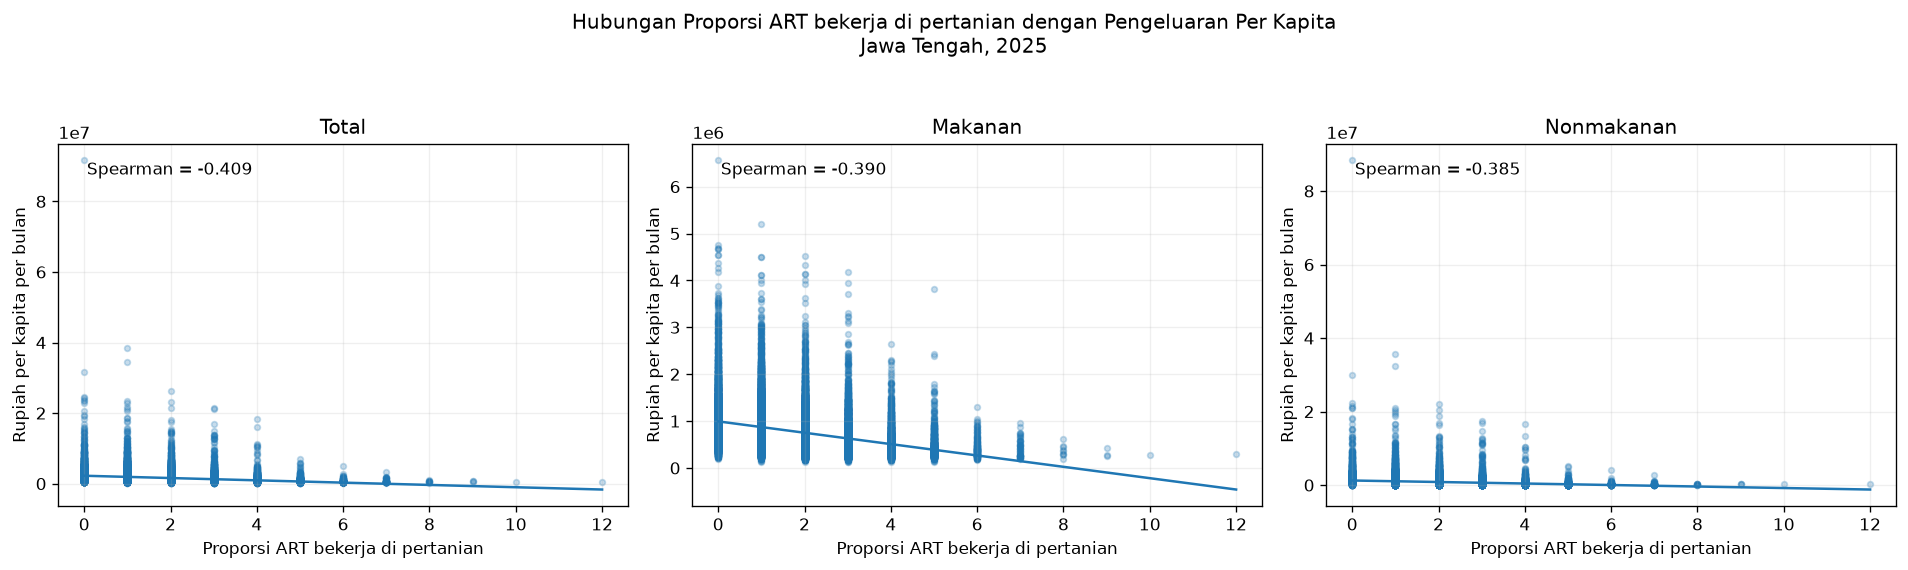

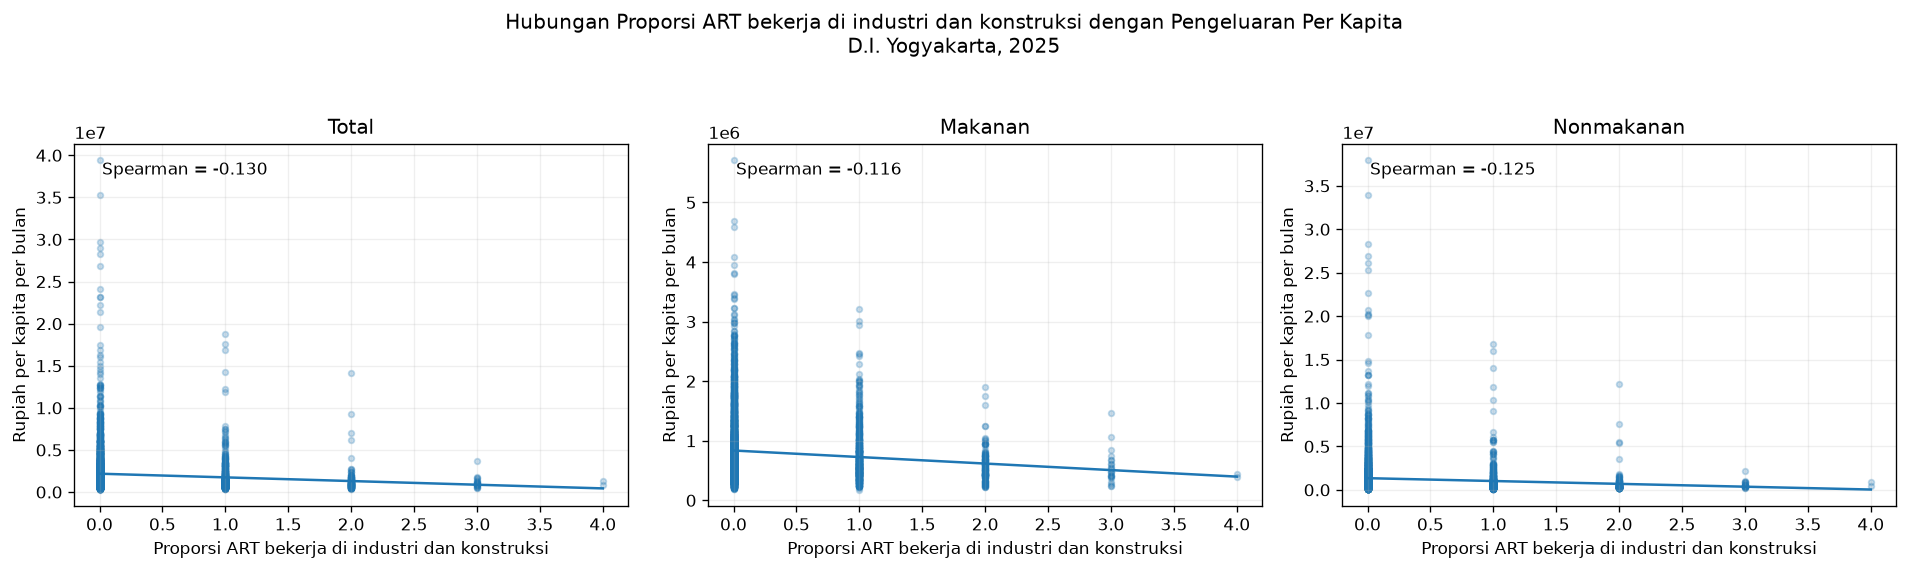

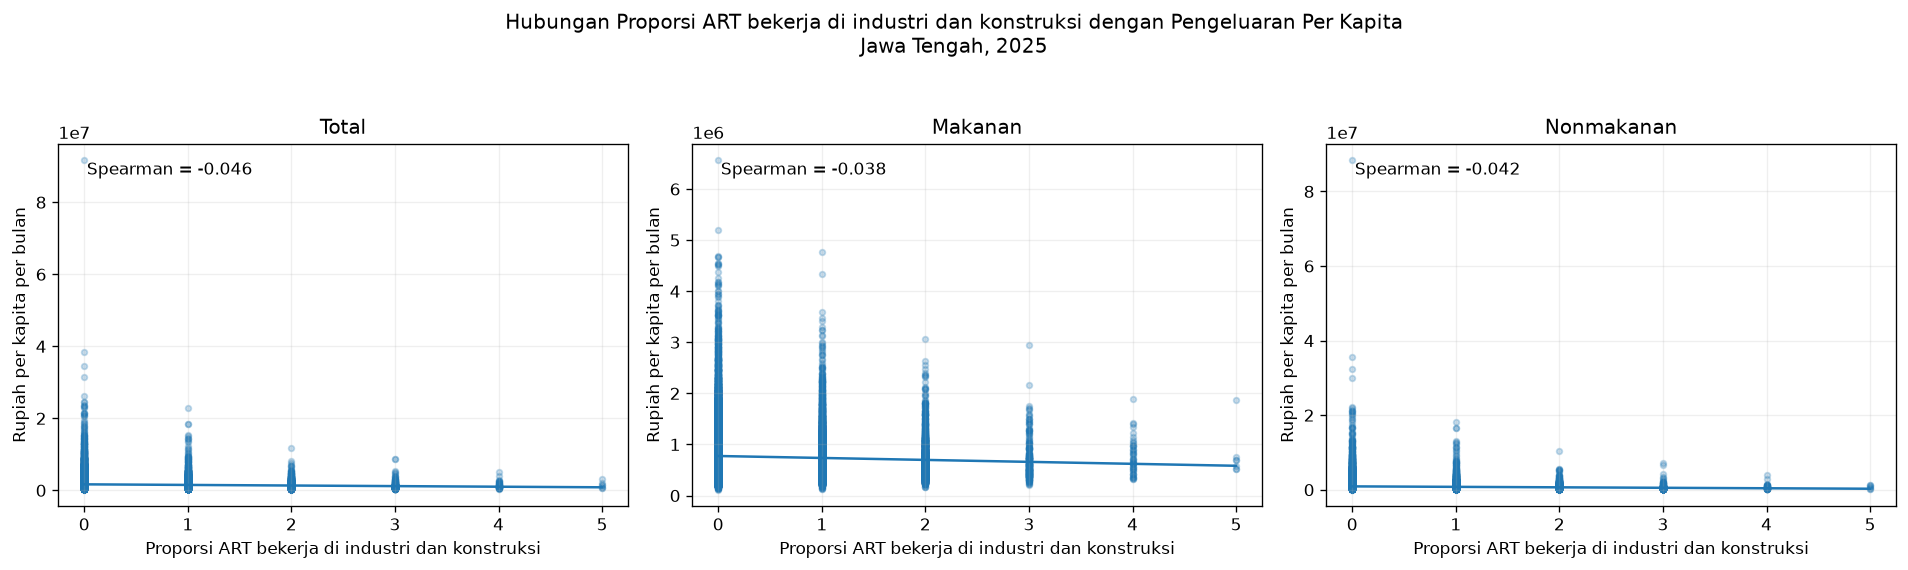

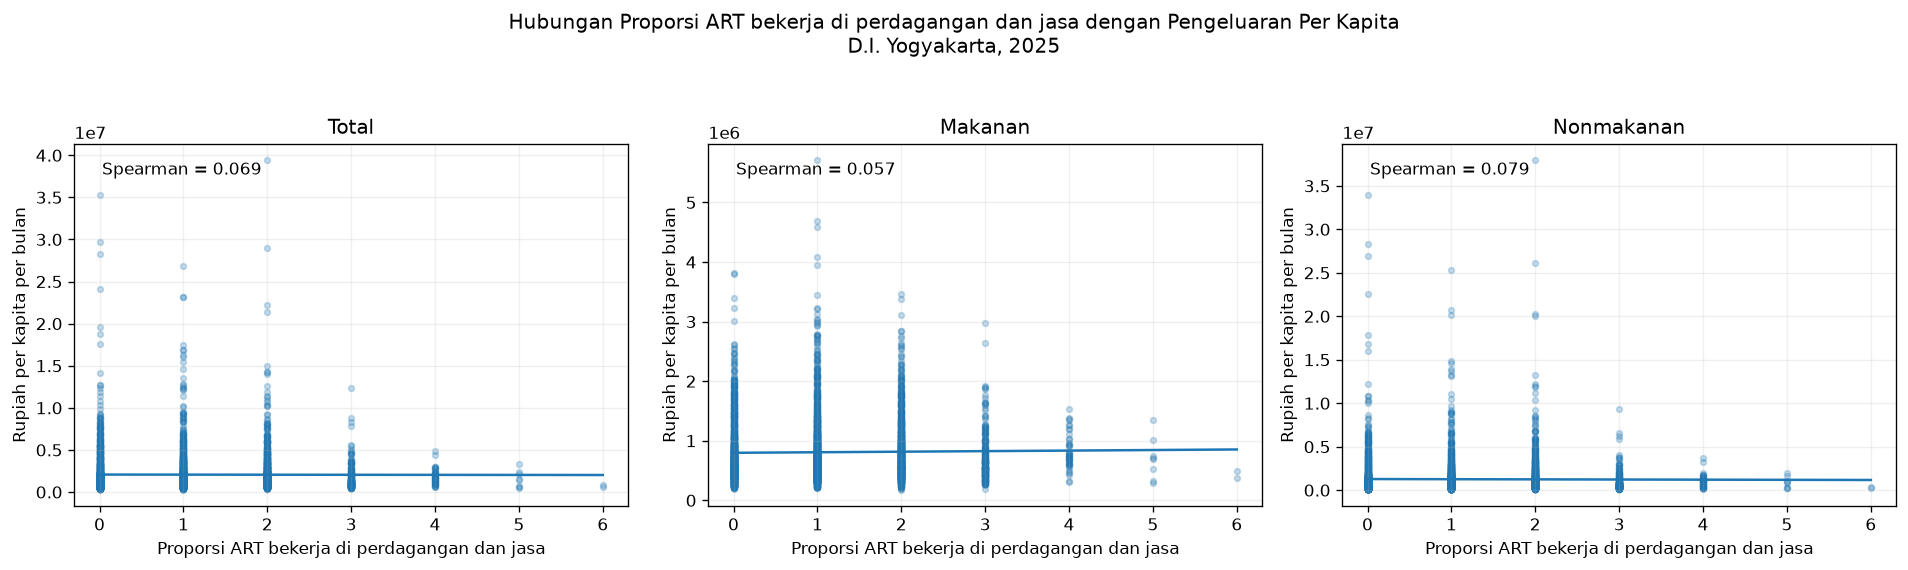

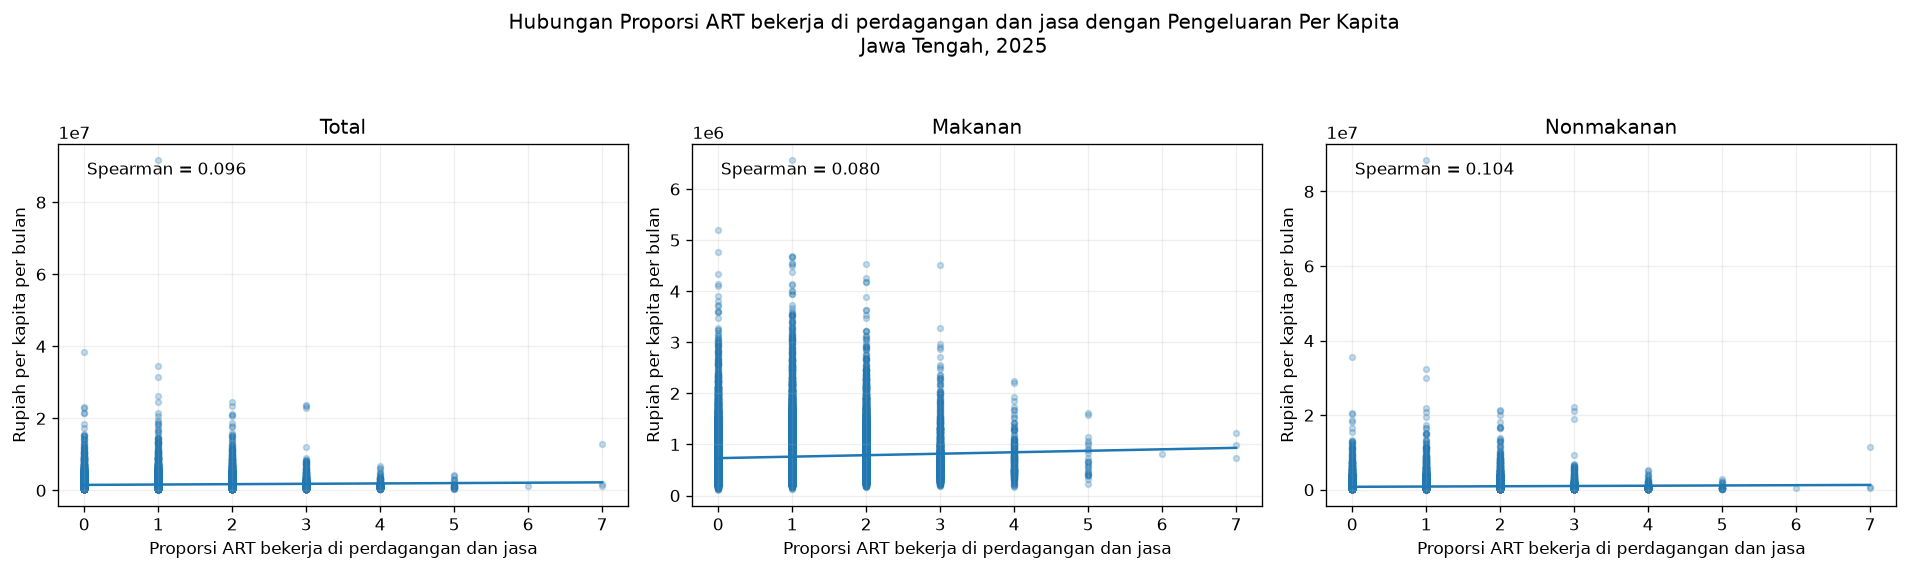

In [13]:
# work_frac sudah berada pada tingkat rumah tangga jika tersedia.
EMPLOYMENT_X = {}

for prov in PROV_ORDER:
    df = data_eda[prov][2025]
    if "work_frac" in df.columns:
        EMPLOYMENT_X["Proporsi ART yang bekerja"] = "work_frac"
        break

employment_corr = spearman_relationship_table(
    data_eda,
    EMPLOYMENT_X
)

display(employment_corr.round(4))

if "work_frac" in EMPLOYMENT_X.values():
    plot_numeric_x_y(
        data_eda,
        "Proporsi ART yang bekerja",
        "work_frac",
        "hubungan_proporsi_ART_bekerja"
    )

# Proporsi sektor pekerjaan pada level rumah tangga.
SECTOR_X = {
    "Proporsi ART bekerja di pertanian": [
        f"h_sec1_stat{i}" for i in range(1, 7)
    ],
    "Proporsi ART bekerja di industri dan konstruksi": [
        f"h_sec2_stat{i}" for i in range(1, 7)
    ],
    "Proporsi ART bekerja di perdagangan dan jasa": [
        f"h_sec3_stat{i}" for i in range(1, 7)
    ],
}

for label, cols in SECTOR_X.items():
    for prov in PROV_ORDER:
        df = data_eda[prov][2025]
        available = [c for c in cols if c in df.columns]

        if available:
            df[label] = df[available].sum(axis=1)

sector_corr = spearman_relationship_table(
    data_eda,
    {
        label: (
            label
            if all(label in data_eda[prov][2025].columns for prov in PROV_ORDER)
            else cols[0]
        )
        for label, cols in SECTOR_X.items()
    }
)

# Koreksi: hanya tampilkan hasil untuk kolom yang benar-benar dibentuk.
sector_x_real = {}
for label in SECTOR_X:
    # Kolom hasil menggunakan label panjang; aman karena dibuat di atas.
    sector_x_real[label] = label

sector_corr = spearman_relationship_table(
    data_eda,
    sector_x_real
)

display(sector_corr.round(4))

for label in sector_x_real:
    plot_numeric_x_y(
        data_eda,
        label,
        label,
        "hubungan_" + label
    )


### 5.4 Kondisi rumah tangga dan kepemilikan aset

In [17]:
import re

def plot_binary_x_y(data_eda, x_label, x_col, filename_prefix):
    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025].copy()

        if x_col not in df.columns:
            continue

        for value, status in [(0, "Tidak"), (1, "Ya")]:
            d = df[df[x_col] == value]

            for y_label, y_col in Y_VARS.items():
                if y_col not in d.columns:
                    continue

                rows.append({
                    "Provinsi": PROV_LABEL[prov],
                    "Status": status,
                    "Y": y_label,
                    "Mean": d[y_col].mean()
                })

    plot_df = pd.DataFrame(rows)

    if plot_df.empty:
        return

    fig, axes = plt.subplots(1, 3, figsize=(15, 5))

    statuses = ["Tidak", "Ya"]
    x = np.arange(len(statuses))
    width = 0.35

    for ax, y_label in zip(axes, Y_VARS.keys()):

        temp = plot_df[plot_df["Y"] == y_label]

        for i, prov in enumerate(PROV_ORDER):

            prov_label = PROV_LABEL[prov]

            d = (
                temp[temp["Provinsi"] == prov_label]
                .set_index("Status")
                .reindex(statuses)
            )

            means = d["Mean"].values

            offset = (i - 0.5) * width

            ax.bar(
                x + offset,
                means,
                width=width,
                label=prov_label
            )

        ax.set_title(y_label)
        ax.set_xticks(x)
        ax.set_xticklabels(statuses)
        ax.set_ylabel("Rata-rata pengeluaran per kapita per bulan")
        ax.grid(axis="y", alpha=0.2)

    axes[-1].legend()

    fig.suptitle(
        f"Rata-rata Pengeluaran Per Kapita Menurut {x_label}, 2025"
    )

    fig.tight_layout(rect=[0, 0, 1, 0.94])

    safe = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        filename_prefix
    ).strip("_")

    fig.savefig(
        FIG_PATH / f"{safe}_2025.png",
        bbox_inches="tight"
    )

    plt.show()


=== AC ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,AC,Tidak,3485,1711118.45,746283.69,964834.76
1,D.I. Yogyakarta,AC,Ya,454,4807977.96,1282590.24,3525387.72
2,Jawa Tengah,AC,Tidak,27434,1458461.70,725682.24,732779.46
3,Jawa Tengah,AC,Ya,1841,3936291.44,1276576.30,2659715.14


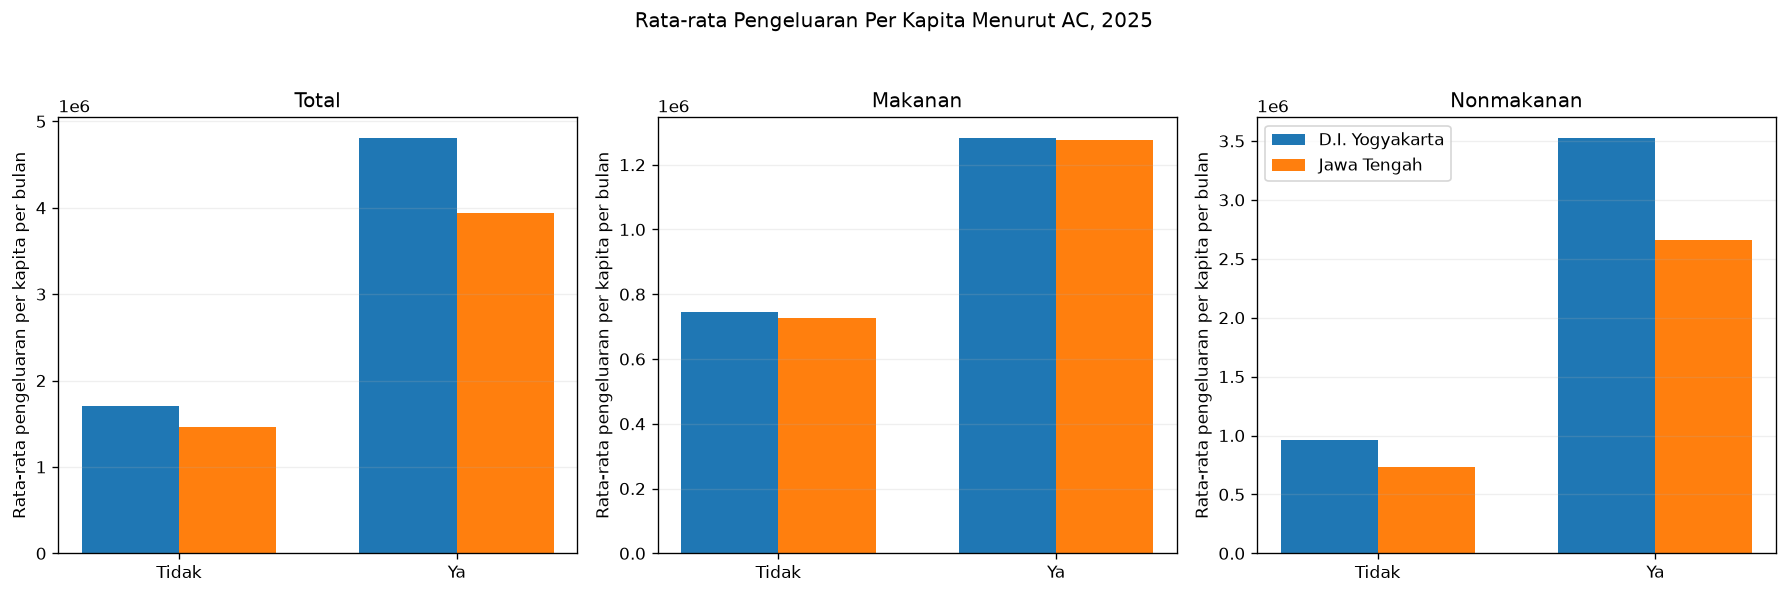


=== Mobil ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Mobil,Tidak,3155,1665023.15,730956.66,934066.49
1,D.I. Yogyakarta,Mobil,Ya,784,3689951.19,1118528.54,2571422.66
2,Jawa Tengah,Mobil,Tidak,25383,1383911.93,708697.08,675214.86
3,Jawa Tengah,Mobil,Ya,3892,3116730.26,1097041.55,2019688.72


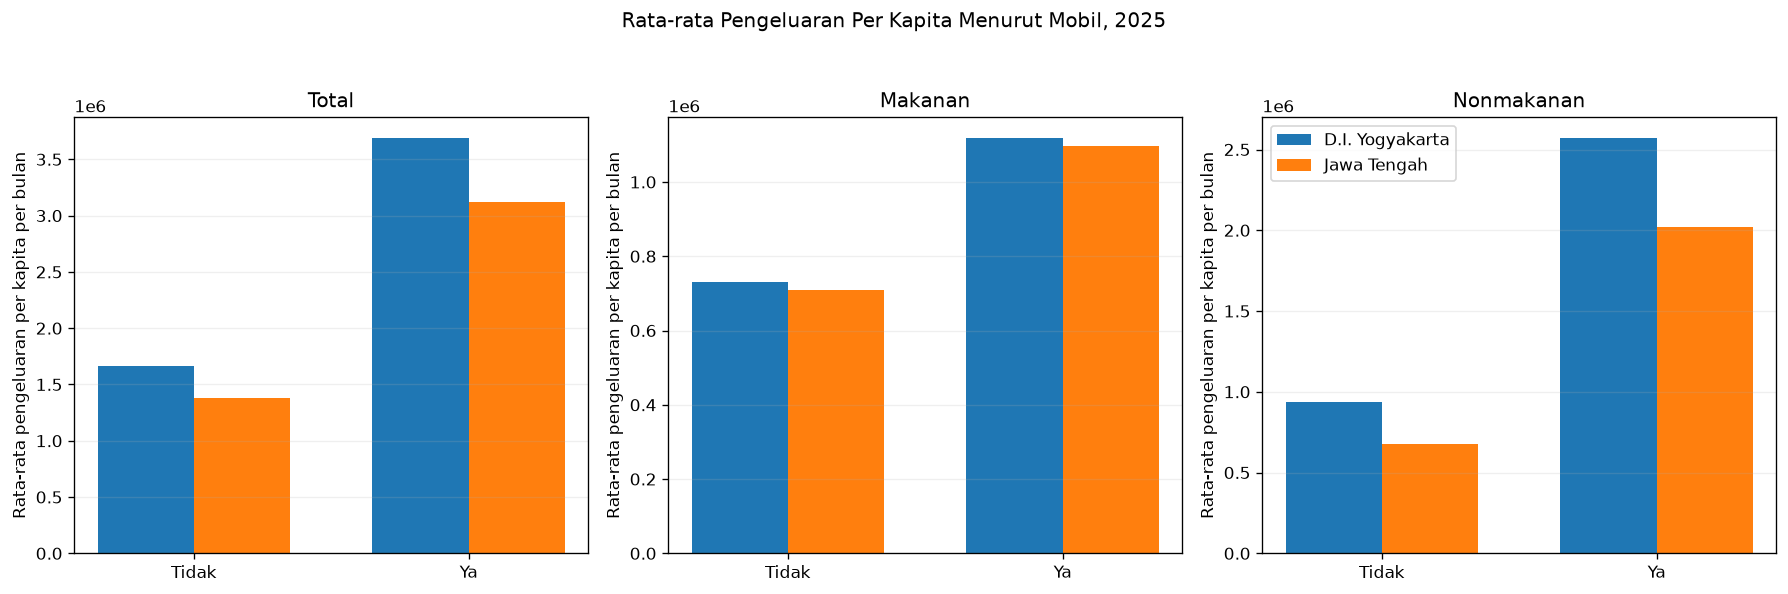


=== Komputer/laptop ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Komputer/laptop,Tidak,2769,1532546.72,702026.40,830520.32
1,D.I. Yogyakarta,Komputer/laptop,Ya,1170,3335425.57,1059131.21,2276294.36
2,Jawa Tengah,Komputer/laptop,Tidak,24564,1397937.16,713402.61,684534.55
3,Jawa Tengah,Komputer/laptop,Ya,4711,2742352.44,1004992.94,1737359.50


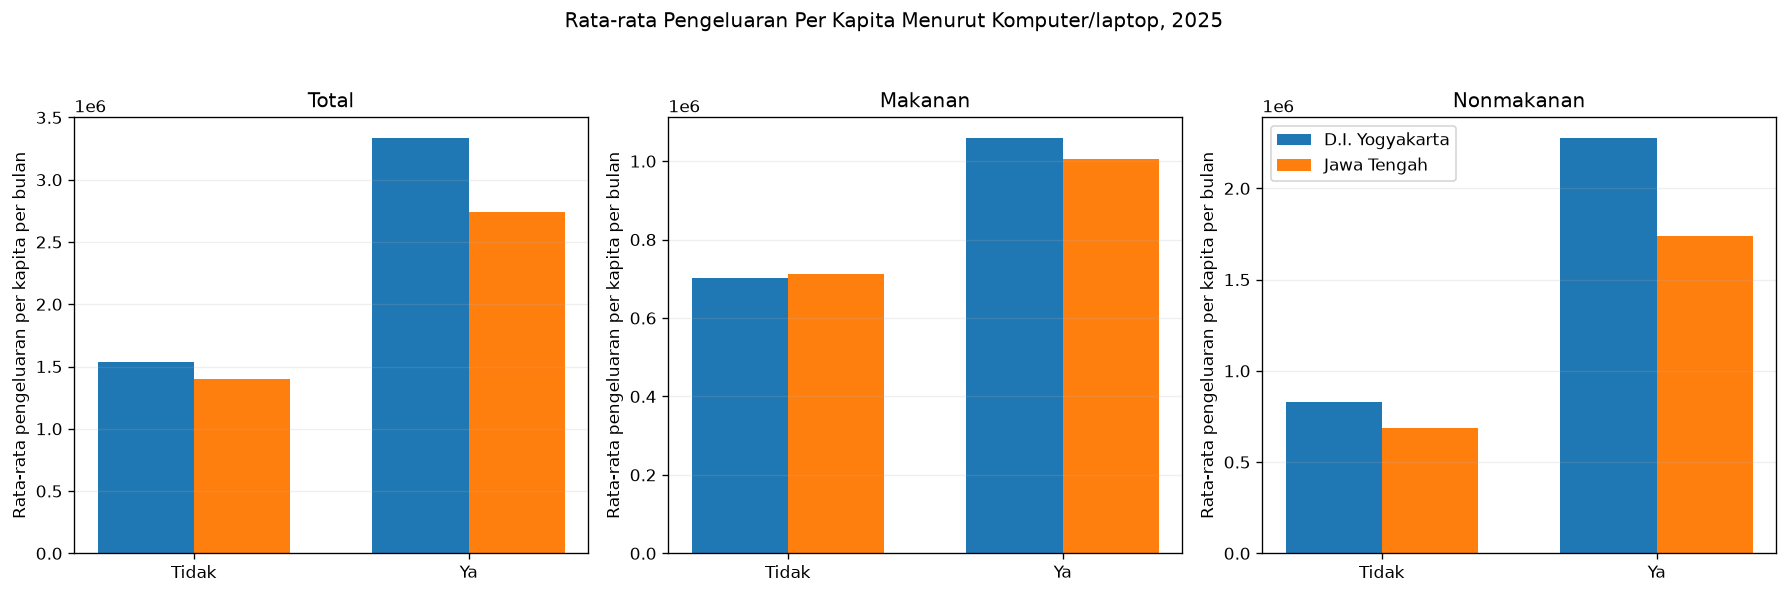


=== Emas/perhiasan ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Emas/perhiasan,Tidak,3059,1714132.11,739840.53,974291.58
1,D.I. Yogyakarta,Emas/perhiasan,Ya,880,3298340.52,1045366.41,2252974.10
2,Jawa Tengah,Emas/perhiasan,Tidak,24364,1413914.84,710765.27,703149.57
3,Jawa Tengah,Emas/perhiasan,Ya,4911,2608334.29,1006202.10,1602132.19


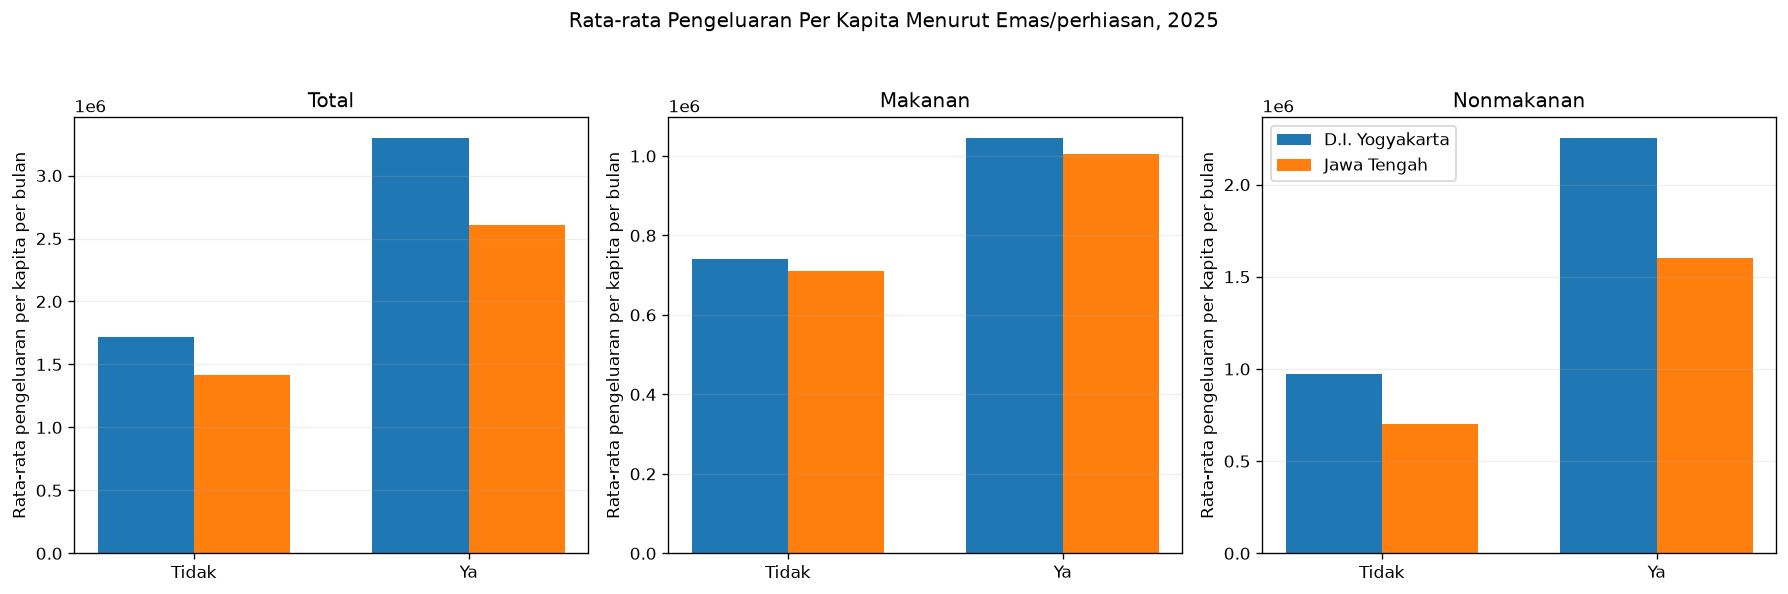


=== Sepeda motor ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Sepeda motor,Tidak,606,1816850.53,725780.92,1091069.60
1,D.I. Yogyakarta,Sepeda motor,Ya,3333,2113728.88,823063.72,1290665.16
2,Jawa Tengah,Sepeda motor,Tidak,4832,1438399.84,708437.78,729962.06
3,Jawa Tengah,Sepeda motor,Ya,24443,1649053.01,770583.49,878469.52


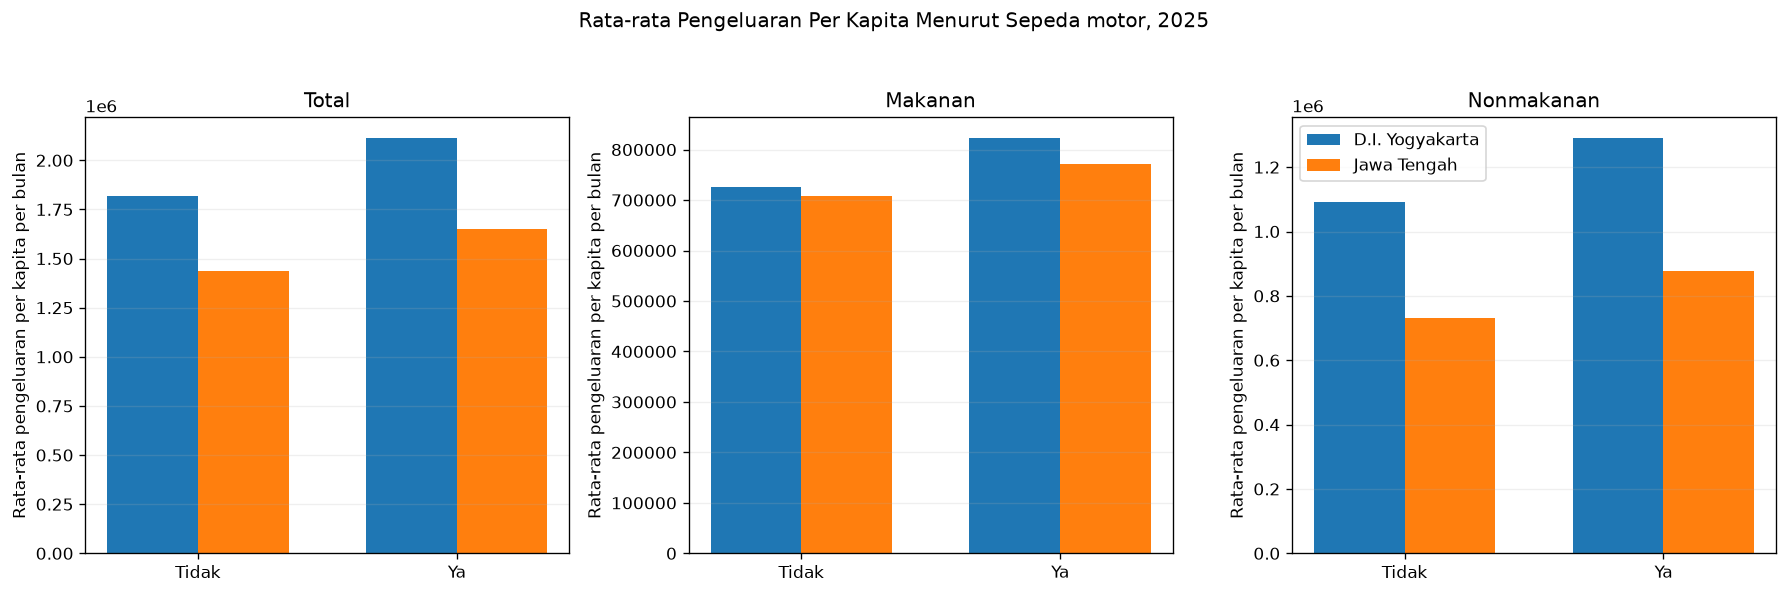


=== Smartphone ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Smartphone,Tidak,418,1303966.63,664338.28,639628.35
1,D.I. Yogyakarta,Smartphone,Ya,3521,2158765.05,825163.65,1333601.39
2,Jawa Tengah,Smartphone,Tidak,3333,1285535.49,685579.88,599955.61
3,Jawa Tengah,Smartphone,Ya,25942,1656520.74,769929.30,886591.44


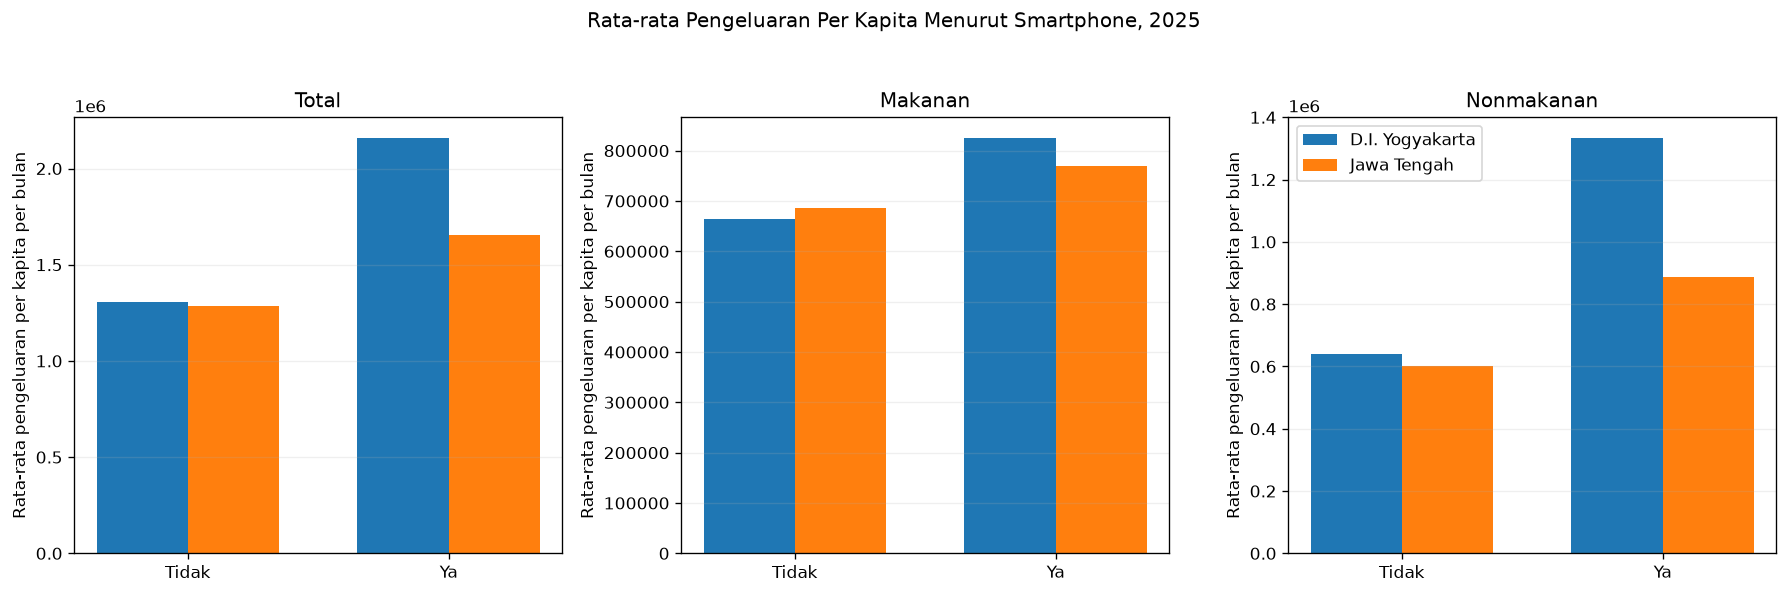


=== Tanah ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Tanah,Tidak,1116,2142818.78,837799.57,1305019.21
1,D.I. Yogyakarta,Tanah,Ya,2823,2038499.48,796355.05,1242144.43
2,Jawa Tengah,Tanah,Tidak,5367,1461876.54,726995.14,734881.40
3,Jawa Tengah,Tanah,Ya,23908,1648496.71,767808.29,880688.42


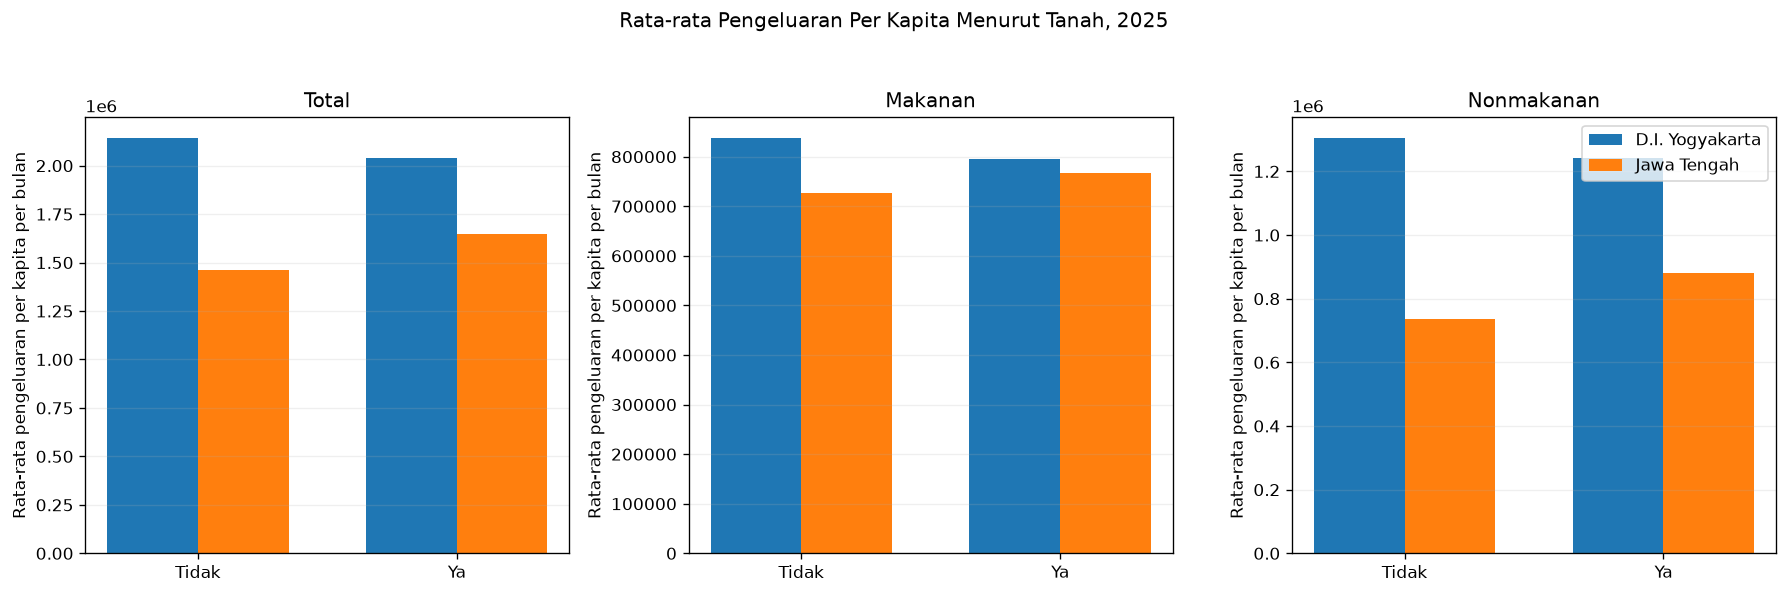


=== Kulkas ===


,Provinsi,Karakteristik,Status X,N,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,Kulkas,Tidak,1072,1780453.68,759835.98,1020617.70
1,D.I. Yogyakarta,Kulkas,Ya,2867,2175592.41,826142.47,1349449.94
2,Jawa Tengah,Kulkas,Tidak,7896,1184134.27,650477.26,533657.02
3,Jawa Tengah,Kulkas,Ya,21379,1773152.47,800896.92,972255.55


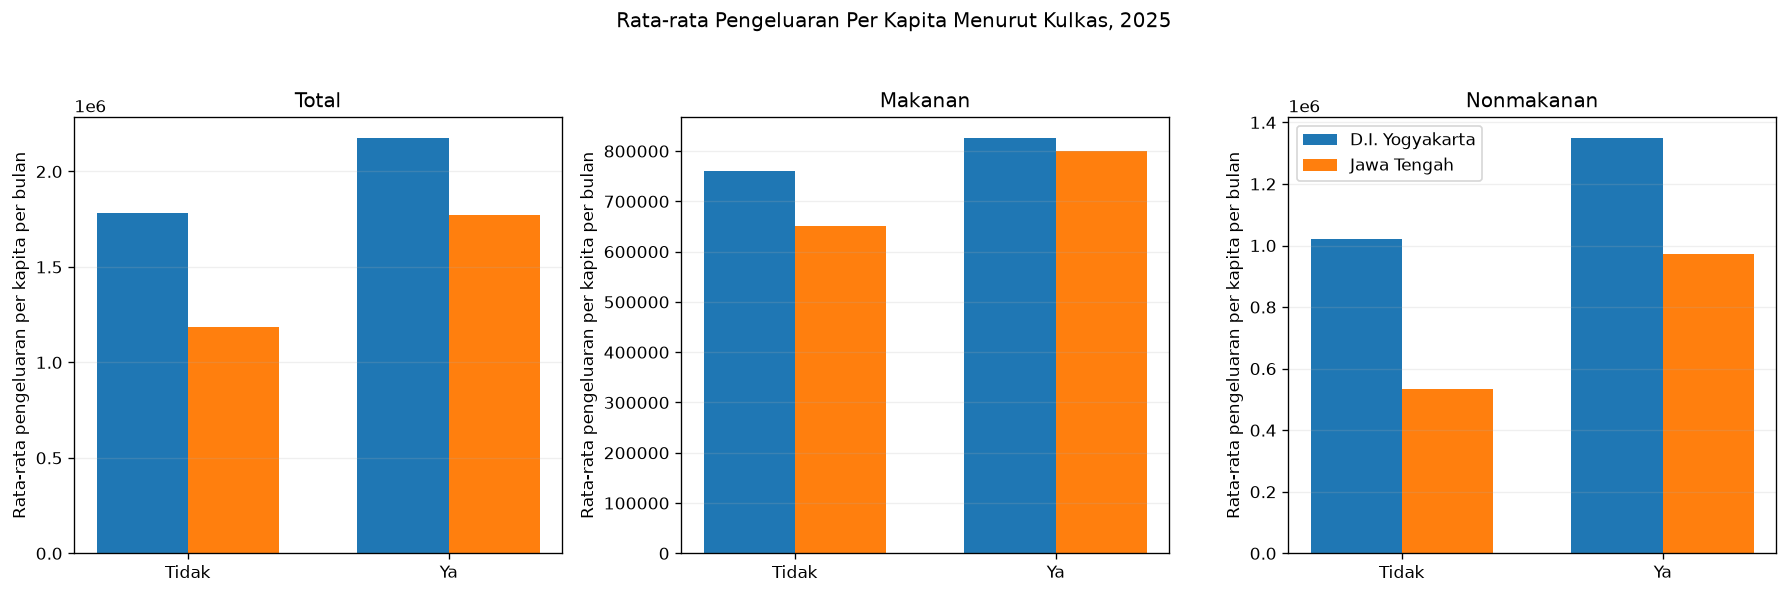

In [18]:
ASSET_X = {
    "AC": "h_asset_ac",
    "Mobil": "h_asset_car",
    "Komputer/laptop": "h_asset_computer",
    "Emas/perhiasan": "h_asset_jewelry",
    "Sepeda motor": "h_asset_motorcycle",
    "Smartphone": "h_asset_smartphone",
    "Tanah": "h_asset_land",
    "Kulkas": "h_asset_fridge",
}

asset_relationship_tables = {}

for label, col in ASSET_X.items():

    available_any = any(
        col in data_eda[prov][2025].columns
        for prov in PROV_ORDER
    )

    if not available_any:
        continue

    asset_relationship_tables[label] = binary_group_mean_table(
        data_eda,
        label,
        col
    )

    print(f"\n=== {label} ===")
    display(
        asset_relationship_tables[label].round(2)
    )

    # INI YANG TADI KURANG
    plot_binary_x_y(
        data_eda,
        label,
        col,
        "hubungan_kepemilikan_" + label
    )

### 5.5 Korelasi ringkas karakteristik sosial ekonomi dengan tiga Y

### 5.6 Perbandingan rata-rata pengeluaran berdasarkan kepemilikan aset

## 6. Karakteristik Rumah Tangga pada Kelompok 40 Persen Terbawah

Bagian ini dipertahankan dari notebook sebelumnya untuk analisis kelompok 40% terbawah.


## 6. Karakteristik Rumah Tangga pada Kelompok 40 Persen Terbawah

In [30]:
# ============================================================
# MEMBENTUK DESIL DAN KELOMPOK 40% TERBAWAH
# Berdasarkan pengeluaran per kapita aktual tahun 2025
# Desil dibentuk di masing-masing kabupaten/kota
# ============================================================

def add_welfare_group(df):
    df = df.copy()

    # Pastikan kode kabupaten/kota tersedia
    if "R102" in df.columns:
        kab_col = "R102"
    elif "r102" in df.columns:
        kab_col = "r102"
    else:
        raise KeyError("Kolom kode kabupaten/kota R102 tidak ditemukan.")

    # Pengeluaran per kapita aktual yang digunakan
    expenditure_col = "total_pc_adj"

    # Buang observasi tanpa pengeluaran
    valid = df[expenditure_col].notna()

    df["desil_total"] = np.nan

    # Desil dibentuk secara terpisah pada setiap kabupaten/kota
    df.loc[valid, "desil_total"] = (
        df.loc[valid]
        .groupby(kab_col)[expenditure_col]
        .transform(
            lambda x: pd.qcut(
                x.rank(method="first"),
                q=10,
                labels=False
            ) + 1
        )
    )

    # Desil 1-4 = 40% terbawah
    df["group40"] = np.where(
        df["desil_total"].isna(),
        np.nan,
        (df["desil_total"] <= 4).astype(int)
    )

    df["kelompok40"] = df["group40"].map({
        1: "40% Terbawah",
        0: "60% Teratas",
    })

    return df


# Tambahkan ke data EDA 2025
for prov in PROV_ORDER:
    data_eda[prov][2025] = add_welfare_group(
        data_eda[prov][2025]
    )

In [31]:
def check_group40(data_eda):
    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025]

        n_total = df["group40"].notna().sum()
        n_40 = (df["group40"] == 1).sum()
        n_60 = (df["group40"] == 0).sum()

        rows.append({
            "Provinsi": PROV_LABEL[prov],
            "Jumlah Ruta": n_total,
            "40% Terbawah": n_40,
            "60% Teratas": n_60,
            "Persentase 40%": n_40 / n_total * 100
        })

    return pd.DataFrame(rows)


tabel_group40 = check_group40(data_eda)

display(tabel_group40.round(2))

,Provinsi,Jumlah Ruta,40% Terbawah,60% Teratas,Persentase 40%
0,D.I. Yogyakarta,3939,1576,2363,40.01
1,Jawa Tengah,29275,11714,17561,40.01


In [35]:
# ============================================================
# RATA-RATA PENGELUARAN MENURUT KELOMPOK 40% TERBAWAH
# VS 60% TERATAS
# ============================================================

def expenditure_group40_table(data_eda):
    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025].copy()

        for group_value, group_label in [
            (1, "40% Terbawah"),
            (0, "60% Teratas")
        ]:
            d = df[df["group40"] == group_value].copy()

            if d.empty:
                continue

            total_mean = d["total_pc_adj"].mean()
            food_mean = d["food_pc_adj"].mean()
            nonfood_mean = d["nonfood_pc_adj"].mean()

            rows.append({
                "Provinsi": PROV_LABEL[prov],
                "Kelompok": group_label,
                "Jumlah Ruta": len(d),
                "Rata-rata Total": total_mean,
                "Rata-rata Makanan": food_mean,
                "Rata-rata Nonmakanan": nonfood_mean
            })

    return pd.DataFrame(rows)


tabel_pengeluaran_group40 = expenditure_group40_table(
    data_eda
)

display(
    tabel_pengeluaran_group40.round(2)
)

,Provinsi,Kelompok,Jumlah Ruta,Rata-rata Total,Rata-rata Makanan,Rata-rata Nonmakanan
0,D.I. Yogyakarta,40% Terbawah,1576,835837.41,477537.13,358300.28
1,D.I. Yogyakarta,60% Teratas,2363,2889881.52,1028563.74,1861317.78
2,Jawa Tengah,40% Terbawah,11714,741491.21,437649.19,303842.02
3,Jawa Tengah,60% Teratas,17561,2196476.44,975566.37,1220910.08


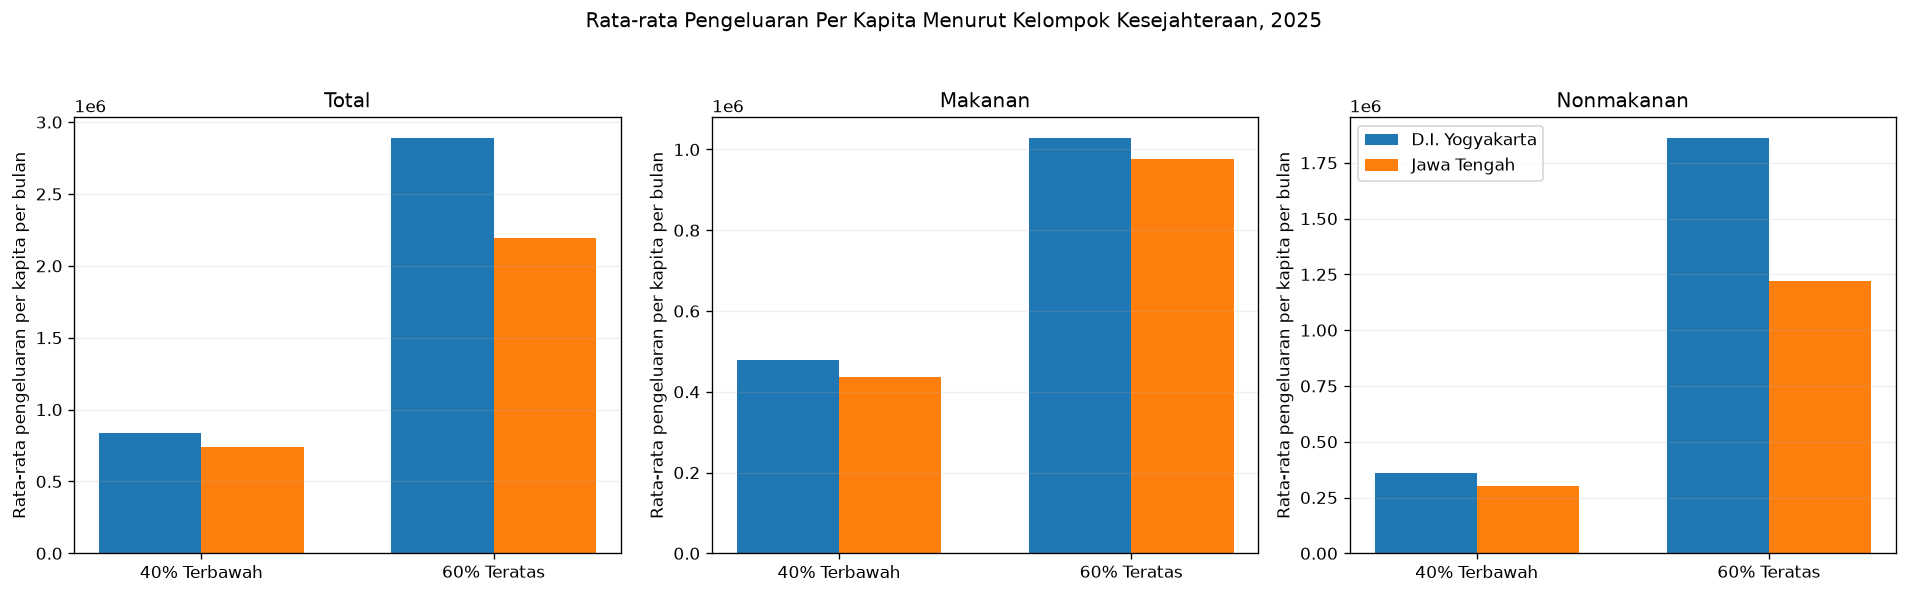

In [36]:
# ============================================================
# GRAFIK RATA-RATA PENGELUARAN
# 40% TERBAWAH VS 60% TERATAS
# ============================================================

def plot_expenditure_group40(data_eda, filename_prefix="pengeluaran_group40"):

    rows = []

    for prov in PROV_ORDER:
        df = data_eda[prov][2025].copy()

        for group_value, group_label in [
            (1, "40% Terbawah"),
            (0, "60% Teratas")
        ]:
            d = df[df["group40"] == group_value]

            if d.empty:
                continue

            rows.append({
                "Provinsi": PROV_LABEL[prov],
                "Kelompok": group_label,
                "Total": d["total_pc_adj"].mean(),
                "Makanan": d["food_pc_adj"].mean(),
                "Nonmakanan": d["nonfood_pc_adj"].mean()
            })

    plot_df = pd.DataFrame(rows)

    fig, axes = plt.subplots(
        1, 3,
        figsize=(16, 5)
    )

    groups = ["40% Terbawah", "60% Teratas"]
    x = np.arange(len(groups))
    width = 0.35

    y_vars = [
        ("Total", "Total"),
        ("Makanan", "Makanan"),
        ("Nonmakanan", "Nonmakanan")
    ]

    for ax, (col, title) in zip(axes, y_vars):

        temp = plot_df[["Provinsi", "Kelompok", col]].copy()

        for i, prov in enumerate(PROV_ORDER):

            prov_label = PROV_LABEL[prov]

            d = (
                temp[temp["Provinsi"] == prov_label]
                .set_index("Kelompok")
                .reindex(groups)
            )

            offset = (i - 0.5) * width

            ax.bar(
                x + offset,
                d[col].values,
                width=width,
                label=prov_label
            )

        ax.set_title(title)
        ax.set_xticks(x)
        ax.set_xticklabels(groups)
        ax.set_ylabel(
            "Rata-rata pengeluaran per kapita per bulan"
        )
        ax.grid(
            axis="y",
            alpha=0.2
        )

    axes[-1].legend()

    fig.suptitle(
        "Rata-rata Pengeluaran Per Kapita Menurut Kelompok Kesejahteraan, 2025"
    )

    plt.tight_layout(
        rect=[0, 0, 1, 0.94]
    )

    safe = re.sub(
        r"[^A-Za-z0-9]+",
        "_",
        filename_prefix
    ).strip("_")

    fig.savefig(
        FIG_PATH / f"{safe}_2025.png",
        bbox_inches="tight"
    )

    plt.show()


plot_expenditure_group40(data_eda)

In [33]:
# ============================================================
# GRAFIK PENDIDIKAN SMA KE ATAS:
# 40% TERBAWAH VS 60% LAINNYA
# ============================================================

rows = []

for prov in PROV_ORDER:
    df = data_eda[prov][2025].copy()

    for group_value, group_label in [
        (1, "40% Terbawah"),
        (0, "60% Teratas")
    ]:

        d = df[df["group40"] == group_value]

        # Proporsi ART dengan ijazah SMA, Diploma, atau Sarjana
        sma_atas = (
            d["h_ngrad_sma"]
            + d["h_ngrad_d"]
            + d["h_ngrad_s"]
        ).mean() * 100

        rows.append({
            "Provinsi": PROV_LABEL[prov],
            "Kelompok": group_label,
            "SMA ke Atas": sma_atas
        })


df_pendidikan40 = pd.DataFrame(rows)

display(df_pendidikan40.round(2))

,Provinsi,Kelompok,SMA ke Atas
0,D.I. Yogyakarta,40% Terbawah,31.60
1,D.I. Yogyakarta,60% Teratas,53.94
2,Jawa Tengah,40% Terbawah,18.38
3,Jawa Tengah,60% Teratas,33.15


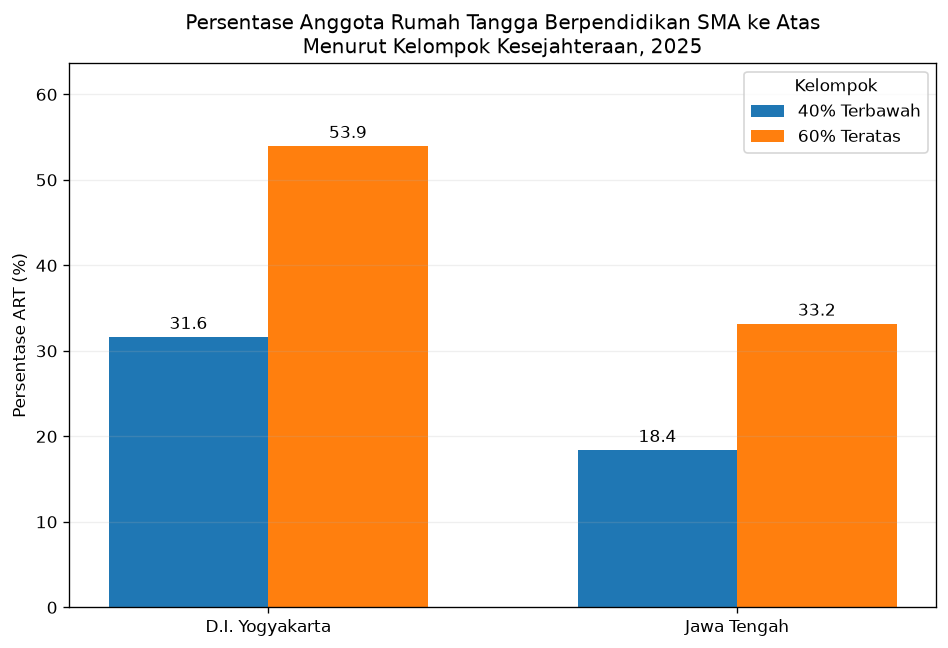

In [19]:
fig, ax = plt.subplots(figsize=(8, 5.5))

provinsi = PROV_ORDER
x = np.arange(len(provinsi))
width = 0.34

nilai_40 = []
nilai_60 = []

for prov in provinsi:
    nama_prov = PROV_LABEL[prov]

    nilai_40.append(
        df_pendidikan40.loc[
            (df_pendidikan40["Provinsi"] == nama_prov) &
            (df_pendidikan40["Kelompok"] == "40% Terbawah"),
            "SMA ke Atas"
        ].iloc[0]
    )

    nilai_60.append(
        df_pendidikan40.loc[
            (df_pendidikan40["Provinsi"] == nama_prov) &
            (df_pendidikan40["Kelompok"] == "60% Lainnya"),
            "SMA ke Atas"
        ].iloc[0]
    )


bars1 = ax.bar(
    x - width/2,
    nilai_40,
    width,
    label="40% Terbawah"
)

bars2 = ax.bar(
    x + width/2,
    nilai_60,
    width,
    label="60% Teratas"
)

# Label sumbu
ax.set_ylabel("Persentase ART (%)")
ax.set_xticks(x)
ax.set_xticklabels([
    "D.I. Yogyakarta",
    "Jawa Tengah"
])

ax.set_title(
    "Persentase Anggota Rumah Tangga Berpendidikan SMA ke Atas\n"
    "Menurut Kelompok Kesejahteraan, 2025"
)

ax.legend(title="Kelompok")
ax.grid(axis="y", alpha=0.2)

# Angka di atas batang
for bars in [bars1, bars2]:
    for bar in bars:
        height = bar.get_height()

        ax.text(
            bar.get_x() + bar.get_width()/2,
            height + 0.5,
            f"{height:.1f}",
            ha="center",
            va="bottom",
            fontsize=10
        )

# Beri ruang agar label angka tidak terpotong
ax.set_ylim(
    0,
    max(nilai_40 + nilai_60) * 1.18
)

fig.tight_layout()

fig.savefig(
    FIG_PATH / "pendidikan_sma_atas_40vs60_2025.png",
    bbox_inches="tight"
)

plt.show()

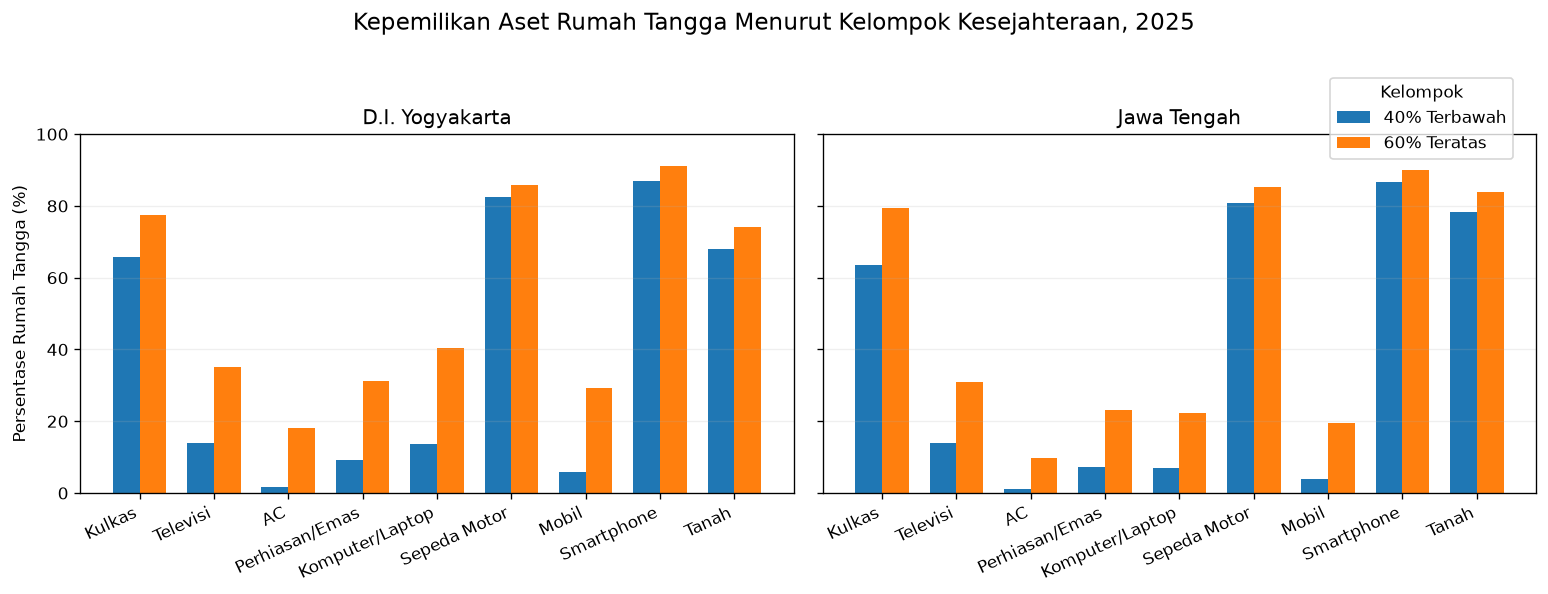

In [24]:
def plot_assets_group40(data_eda):

    asset_vars = {
        "Kulkas": "h_asset_fridge",
        "Televisi": "h_asset_tv",
        "AC": "h_asset_ac",
        "Perhiasan/Emas": "h_asset_jewelry",
        "Komputer/Laptop": "h_asset_computer",
        "Sepeda Motor": "h_asset_motorcycle",
        "Mobil": "h_asset_car",
        "Smartphone": "h_asset_smartphone",
        "Tanah": "h_asset_land",

    }

    fig, axes = plt.subplots(
        1, 2,
        figsize=(13, 5),
        sharey=True
    )

    for ax, prov in zip(axes, PROV_ORDER):

        df = data_eda[prov][2025]

        rows = []

        for asset_label, var in asset_vars.items():

            for group_value, group_label in [
                (1, "40% Terbawah"),
                (0, "60% Teratas")
            ]:

                value = (
                    df.loc[df["group40"] == group_value, var]
                    .mean()
                    * 100
                )

                rows.append({
                    "Aset": asset_label,
                    "Kelompok": group_label,
                    "Persentase": value
                })

        plot_df = pd.DataFrame(rows)

        x = np.arange(len(asset_vars))
        width = 0.36

        bottom40 = (
            plot_df[
                plot_df["Kelompok"] == "40% Terbawah"
            ]["Persentase"]
            .to_numpy()
        )

        other60 = (
            plot_df[
                plot_df["Kelompok"] == "60% Teratas"
            ]["Persentase"]
            .to_numpy()
        )

        ax.bar(
            x - width / 2,
            bottom40,
            width,
            label="40% Terbawah"
        )

        ax.bar(
            x + width / 2,
            other60,
            width,
            label="60% Teratas"
        )

        ax.set_title(PROV_LABEL[prov])
        ax.set_xticks(x)
        ax.set_xticklabels(
            list(asset_vars.keys()),
            rotation=25,
            ha="right"
        )

        ax.set_ylim(0, 100)
        ax.grid(axis="y", alpha=0.2)

    axes[0].set_ylabel("Persentase Rumah Tangga (%)")

    axes[1].legend(
        title="Kelompok",
        loc="upper right",
        bbox_to_anchor=(0.98, 1.18)
    )

    fig.suptitle(
        "Kepemilikan Aset Rumah Tangga Menurut Kelompok Kesejahteraan, 2025",
        fontsize=14
    )

    fig.tight_layout()

    fig.savefig(
        FIG_PATH / "aset_bottom40_vs_60_2025.png",
        bbox_inches="tight"
    )

    plt.show()


plot_assets_group40(data_eda)

## 7. Simpan seluruh tabel ke Excel


In [2]:
# ============================================================
# 7. SIMPAN HASIL EDA KE EXCEL
# ============================================================

excel_path = OUTPUT_PATH / "EDA_4_1_Hubungan_X_Y_2025.xlsx"

with pd.ExcelWriter(excel_path, engine="openpyxl") as writer:

    tabel_sampel.to_excel(
        writer,
        sheet_name="sampel",
        index=False
    )

    tabel_tren.to_excel(
        writer,
        sheet_name="tren_pengeluaran",
        index=False
    )

    tabel_deskriptif_2025.round(2).to_excel(
        writer,
        sheet_name="deskriptif_2025",
        index=False
    )

    tabel_hubungan_XY.round(4).to_excel(
        writer,
        sheet_name="hubungan_proporsi_XY",
        index=False
    )

    tabel_aset_XY.round(2).to_excel(
        writer,
        sheet_name="hubungan_aset_XY",
        index=False
    )

    # Hasil kelompok 40% tetap disimpan
    tabel_group40.round(2).to_excel(
        writer,
        sheet_name="kelompok_40",
        index=False
    )

    tabel_pengeluaran_group40.round(2).to_excel(
        writer,
        sheet_name="pengeluaran_40vs60",
        index=False
    )

    if "tabel_karakteristik_group40" in globals():
        tabel_karakteristik_group40.round(2).to_excel(
            writer,
            sheet_name="karakteristik_40vs60",
            index=False
        )

print("SELESAI")
print("Excel :", excel_path)
print("Grafik:", FIG_PATH)


NameError: name 'OUTPUT_PATH' is not defined